# M06 — Simple Model & Performance Evaluation
**QM 47400 · Group 22-002** — Jeffrey Wan, Nitya Jhaveri, Christopher Weng, Kyle Cuson

This notebook produces every number and figure in `22_simple_model.pdf`: **Section 0** (prediction goal),
**1** (dataset exploration), **2** (feature engineering), **3** (missing values) and **4** (baseline logistic
regression with feature selection inside 5-fold cross-validation).

**Course rules followed**
* **Split before exploring (nb01).** The data are split by fiscal year *before* any feature–target analysis.
  Train = 1999–2013, validation = 2014–2016, test = 2017–2018. Every statistic below uses **training years only**;
  validation and test labels are never examined.
* **All preprocessing inside one `Pipeline` (nb02/nb09).** Winsorizing, imputation and scaling are fit on each
  training fold only.
* **CV-first (nb08).** The feature-engineering impact check in §2.4 uses 5 time-ordered folds inside the training years.

**Data.** Put the Kaggle file at `data/american_bankruptcy.csv` (Lombardo et al., 2022,
*American Companies Bankruptcy Prediction Dataset*). SIC industry codes are merged from the authors' public GitHub
release when an internet connection is available; the notebook runs without them.

### 📝 How to use this notebook (for whoever writes `22_simple_model.pdf`)
* Cells headed **📝 Notes for the report** explain the output directly above them: what it shows, why it matters, and
  sentences you can adapt. Every number quoted in a note comes from this notebook's run on the real data.
* **Figures** are saved in `figures/` (white background, 250 dpi). Suggested placement:

| Figure file | Report section | Shows |
|---|---|---|
| `m06_fig1_problem_shape.png` | 1. Descriptive stats | failures per year; total assets raw vs log |
| `m06_figA_distributions.png` | 1. (appendix) | all 17 raw variables, signed-log scale |
| `m06_fig2_signal.png` | 1. Predictors vs response | univariate AUC; Altman zones; ratios before failure |
| `m06_fig3_correlation.png` | 1. Predictors vs response | Spearman correlation of the 17 ratios |
| `m06_fig4_momentum.png` | 2. Feature engineering | momentum features, survivors vs failures |
| `m06_fig5_fe_impact.png` | 2. Feature engineering | CV PR-AUC of each feature set |
| `m06_fig6_missing.png` | 3. Missing values | CV PR-AUC of each missing-value strategy |
| `m06_fig7_lasso_path.png` | 4b. Implementation | LASSO penalty vs CV PR-AUC and features kept |
| `m06_fig8_model.png` | 4c. Interpretation | precision–recall vs Altman; final coefficients |

* **Key decisions at a glance:** binary response → logistic regression; target rebuilt as "files within one year";
  chronological split (train 1999–2013, validation 2014–2016, test 2017–2018, both locked); primary metric = PR-AUC;
  5 time-ordered CV folds; all preprocessing inside one scikit-learn `Pipeline`; feature selection by LASSO inside CV.
* **Data citation:** Lombardo, G., Pellegrino, M., Adosoglou, G., Cagnoni, S., Pardalos, P. M., & Poggi, A. (2022).
  *Machine Learning for Bankruptcy Prediction in the American Stock Market: Dataset and Benchmarks.* Future Internet,
  14(8), 244. Distributed on Kaggle as "American Companies Bankruptcy Prediction Dataset".

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import skew
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RANDOM_SEED = 474
DATA_PATH = next((p for p in ["data/american_bankruptcy.csv", "../data/american_bankruptcy.csv"] if os.path.exists(p)),
                 "data/american_bankruptcy.csv")   # works from the repo root or from eda/
TRAIN_END, VAL_END = 2013, 2016            # test = 2017–2018 (locked)
os.makedirs("figures", exist_ok=True)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

# Figures: opaque white background, dark high-contrast text
C_ALIVE, C_FAIL, C_VAL, C_LOCK = "#1f5fbf", "#d1495b", "#1a8a5a", "#cfcfcf"
INK, GRID = "#111111", "#dddddd"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "savefig.transparent": False, "text.color": INK, "axes.labelcolor": INK, "axes.edgecolor": INK,
    "xtick.color": INK, "ytick.color": INK, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "legend.frameon": False,
    "figure.dpi": 110,
})

## Section 0 — Prediction goal
**Goal.** For a U.S. public company, use the financial statements in its most recent annual report (fiscal year *t*)
to predict the **probability that it files for Chapter 7 or Chapter 11 bankruptcy within the next year**, then rank
firms by that probability and identify which financial ratios drive the risk.

**Type of problem.** The response is binary (files within a year: yes/no), so this is a **classification** problem,
not regression. Our model outputs a probability, and we evaluate how well it ranks failures above survivors.

**Why it matters.** Lenders, suppliers and investors lose money on every bankruptcy they miss: unpaid loans, unpaid
invoices and wiped-out equity. The industry-standard screen, the 1968 Altman Z-score, catches most failures but flags
far more healthy firms than failing ones, so analysts waste review time on false alarms. A better-ranked, explainable
watch list lets them focus on the firms that are actually at risk.

## Section 1 — Dataset exploration
### 1.1 Load and structural audit
Structural checks only (types, missingness, duplicates, accounting identities). They never relate features to the
target, so they are safe on the full file.

In [2]:
NAMES = {"X1": "current_assets", "X2": "cogs", "X3": "dep_amort", "X4": "ebitda", "X5": "inventory",
         "X6": "net_income", "X7": "receivables", "X8": "market_value", "X9": "net_sales",
         "X10": "total_assets", "X11": "lt_debt", "X12": "ebit", "X13": "gross_profit",
         "X14": "current_liab", "X15": "retained_earn", "X16": "total_revenue",
         "X17": "total_liab", "X18": "total_opex"}
df = pd.read_csv(DATA_PATH).rename(columns=NAMES)

# Optional: SIC industry division from the dataset authors' GitHub release (same firm IDs and years)
GH_URL = "https://raw.githubusercontent.com/sowide/bankruptcy_dataset/main/american_bankruptcy_dataset.csv"
try:
    div = pd.read_csv(GH_URL, usecols=["company_name", "fyear", "Division"]).rename(columns={"fyear": "year"})
    div["year"] = div["year"].astype(int)
    df = df.merge(div.drop_duplicates(["company_name", "year"]), on=["company_name", "year"], how="left")
    HAS_DIVISION = df["Division"].notna().mean() > 0.9
except Exception as e:
    print("Industry codes not attached (no internet or file moved):", type(e).__name__)
    HAS_DIVISION = False
print("Industry division attached:", HAS_DIVISION)

RAW = list(NAMES.values())
tol = dict(rtol=0.005, atol=0.002)
yrs = df.groupby("company_name").year.agg(["min", "max", "count"])
audit = pd.Series({
    "rows (firm-years)": f"{len(df):,}",
    "unique firms": f"{df.company_name.nunique():,}",
    "fiscal years": f"{df.year.min()}–{df.year.max()}",
    "financial columns": len(RAW),
    "missing cells": int(df[RAW].isna().sum().sum()),
    "duplicate firm-years": int(df.duplicated(["company_name", "year"]).sum()),
    "net_sales identical to total_revenue": f"{np.isclose(df.net_sales, df.total_revenue).mean():.1%}",
    "rows breaking gross profit = revenue − COGS": int((~np.isclose(df.gross_profit, df.total_revenue - df.cogs, **tol)).sum()),
    "rows breaking EBIT = EBITDA − D&A": int((~np.isclose(df.ebit, df.ebitda - df.dep_amort, **tol)).sum()),
    "firms with a gap in their year sequence": int(((yrs["max"] - yrs["min"] + 1) != yrs["count"]).sum()),
}, name="value")
audit.to_frame()

Industry division attached: True


,value
rows (firm-years),"78,682"
unique firms,"8,971"
fiscal years,1999–2018
financial columns,18
missing cells,0
duplicate firm-years,0
net_sales identical to total_revenue,100.0%
rows breaking gross profit = revenue − COGS,2
rows breaking EBIT = EBITDA − D&A,3
firms with a gap in their year sequence,710


### 📝 Notes for the report

* **Size:** 78,682 firm-years (one row = one company in one fiscal year), 8,971 companies, fiscal years 1999–2018,
  18 financial variables plus company ID, year and label.
* **Quality:** zero missing cells and zero duplicate firm-years. Only 2 rows break *gross profit = revenue − COGS* and
  3 rows break *EBIT = EBITDA − D&A*, so the file is internally consistent and needs no row-level cleaning.
* **Duplicate column:** `net_sales` (X9) equals `total_revenue` (X16) in 100% of rows, so it is dropped; **17**
  financial variables are used from here on.
* **Gaps:** 710 companies skip at least one year. This matters for the momentum features (Sections 2–3).
* **Industry:** SIC industry division was merged from the dataset authors' public release. It is used for
  exploration only (§1.7), not as a model input at this milestone.

### 1.2 Response variable: building a true one-year-ahead target
The raw `status_label` marks **every** year of a firm that eventually fails as `failed`, including years a decade
before its filing. That does not match a one-year-ahead question, and with a random split a model can simply memorize
which *companies* fail. We therefore set **y = 1 only on a failed firm's last reported year** (the report filed just
before bankruptcy) and y = 0 on all of its earlier years. This defines what we predict; it is applied identically to
every row and is not a fitted preprocessing step.

In [3]:
df = df.sort_values(["company_name", "year"]).reset_index(drop=True)
df["raw_failed"] = (df.status_label == "failed").astype(int)
last_year = df.groupby("company_name").year.transform("max")
df["y"] = ((df.raw_failed == 1) & (df.year == last_year)).astype(int)

print(f"Raw label: {df.raw_failed.sum():,} 'failed' rows ({df.raw_failed.mean():.2%}) "
      f"from {df.loc[df.raw_failed == 1, 'company_name'].nunique()} firms")
print(f"One-year-ahead target y: {df.y.sum():,} positives ({df.y.mean():.2%}) — one per failed firm")

Raw label: 5,220 'failed' rows (6.63%) from 609 firms
One-year-ahead target y: 609 positives (0.77%) — one per failed firm


### 📝 Notes for the report

* **Response variable `y` is binary categorical** (1 = the firm files for Chapter 7/11 bankruptcy within one year of
  this report, 0 = it does not). That makes this a **classification** problem. The model's *output* is a probability of
  failure, but the response in the data is 0/1, so the right model is **logistic regression**, not linear regression
  (linear regression on a 0/1 response can predict values below 0 or above 1).
* **Why we rebuilt the label:** the raw `status_label` marks *every* year of an eventually failing company as
  "failed": 5,220 rows (6.63%) from 609 companies. A firm that files in 2009 is labeled "failed" in 2000 too, when it
  may have looked healthy. With that label a model learns *which companies* fail rather than warning signs: in a
  random 80/20 split, over 99% of "failed" test rows come from a company already seen as failed in training (M02).
* **Our target:** y = 1 only on each failed company's **last** annual report (the one filed just before bankruptcy).
  Result: 609 positives in total, **0.77%** of all firm-years, exactly one per failed company.
* **Assumption to state:** company names are anonymized, so filing dates cannot be checked; we assume a failed firm's
  last report is the one immediately preceding its filing.

### 1.3 Data assembly and the chronological split (done before any exploration)
A firm's prior-year report is public when year *t* is scored, so we attach its **raw** prior-year figures (only when
that report is exactly year *t−1*). No transformation is computed here; ratios and changes are built inside the
pipeline in Section 2. `net_sales` is dropped because it duplicates `total_revenue` in every row.

In [4]:
LAG_SRC = ["total_liab", "total_assets", "net_income", "total_revenue", "market_value"]
prev = df.groupby("company_name")[LAG_SRC + ["year"]].shift(1)
adjacent = (df.year - prev.year) == 1
for c in LAG_SRC:
    df[f"prev_{c}"] = prev[c].where(adjacent)

RAW_KEEP = [c for c in RAW if c != "net_sales"]
INPUT_COLS = RAW_KEEP + [f"prev_{c}" for c in LAG_SRC] + (["Division"] if HAS_DIVISION else [])

df["split"] = np.select([df.year <= TRAIN_END, df.year <= VAL_END], ["train", "validation"], "test")
train = df[df.split == "train"].copy()
ytr = train.y.values

sizes = pd.DataFrame({
    "years": ["1999–2013", "2014–2016", "2017–2018"],
    "firm-years": [len(train), (df.split == "validation").sum(), (df.split == "test").sum()],
    "firms": [train.company_name.nunique(), df.loc[df.split == "validation", "company_name"].nunique(),
              df.loc[df.split == "test", "company_name"].nunique()],
    "failures (y = 1)": [int(train.y.sum()), "locked", "locked"],
}, index=["train", "validation", "test"])
sizes

,years,firm-years,firms,failures (y = 1)
train,1999–2013,62896,8238,457
validation,2014–2016,10049,3888,locked
test,2017–2018,5737,3094,locked


### 📝 Notes for the report

* **Chronological split, made before any exploration:** train 1999–2013 (62,896 firm-years, 8,238 firms,
  **457 failures**), validation 2014–2016 (10,049), test 2017–2018 (5,737).
* **Why by year, not at random:** a lender always scores the future with a model built on the past. A random split would
  let the model learn from 2016 to predict 2005 and would overstate performance.
* **Everything in this notebook uses the training years only.** Validation and test labels are never examined; they
  are reserved for model selection and the final test in later milestones. All performance numbers in Sections 2–4
  come from cross-validation inside 1999–2013, as the course requires.

### 1.4 Dataset overview: every feature, its type and its range (training years)
All 18 financial variables are continuous, in **$ millions**. Ranges are from the training years.

In [5]:
DESC = {
    "current_assets": "Cash and assets convertible to cash within a year",
    "cogs": "Cost of goods sold: direct cost of products sold",
    "dep_amort": "Depreciation & amortization expense",
    "ebitda": "Earnings before interest, taxes, depreciation & amortization",
    "inventory": "Value of unsold goods",
    "net_income": "Bottom-line profit after all expenses and taxes",
    "receivables": "Money owed to the firm by customers",
    "market_value": "Stock price × shares outstanding",
    "net_sales": "Revenue net of returns (duplicate of total_revenue → dropped)",
    "total_assets": "Everything the firm owns",
    "lt_debt": "Debt due after more than one year",
    "ebit": "Operating profit (EBITDA − D&A)",
    "gross_profit": "Revenue − COGS",
    "current_liab": "Obligations due within a year",
    "retained_earn": "Cumulative profits kept in the firm (minus dividends)",
    "total_revenue": "Total sales",
    "total_liab": "Everything the firm owes",
    "total_opex": "Total operating expenses",
}
code_of = {v: k for k, v in NAMES.items()}
feat_tab = pd.DataFrame({
    "Kaggle": [code_of[c] for c in RAW],
    "description": [DESC[c] for c in RAW],
    "type": "continuous ($M)",
    "min": train[RAW].min().values,
    "median": train[RAW].median().values,
    "max": train[RAW].max().values,
    "% zero": (train[RAW].eq(0).mean() * 100).round(1).values,
    "% negative": (train[RAW].lt(0).mean() * 100).round(1).values,
    "skew": train[RAW].apply(skew).round(1).values,
}, index=RAW)
other = pd.DataFrame({
    "description": ["Anonymized firm ID (C_1 … C_8971)", "Fiscal year", "Raw label: alive / failed (every year of a failing firm)",
                    "RESPONSE: 1 = files for bankruptcy within one year (built in §1.2)"]
                   + (["SIC industry division (merged)"] if HAS_DIVISION else []),
    "type": ["identifier", "integer (time index)", "categorical (2 levels)", "binary categorical"]
            + (["categorical (10 levels)"] if HAS_DIVISION else []),
}, index=["company_name", "year", "status_label", "y"] + (["Division"] if HAS_DIVISION else []))
display(other)
feat_tab.round(2)

,description,type
company_name,Anonymized firm ID (C_1 … C_8971),identifier
year,Fiscal year,integer (time index)
status_label,Raw label: alive / failed (every year of a fai...,categorical (2 levels)
y,RESPONSE: 1 = files for bankruptcy within one ...,binary categorical
Division,SIC industry division (merged),categorical (10 levels)


,Kaggle,description,type,min,median,max,% zero,% negative,skew
current_assets,X1,Cash and assets convertible to cash within a year,continuous ($M),-0.01,88.32,101466.00,0.0,0.0,12.5
cogs,X2,Cost of goods sold: direct cost of products sold,continuous ($M),-366.64,93.03,349199.00,0.3,0.0,22.1
dep_amort,X3,Depreciation & amortization expense,continuous ($M),0.00,6.97,21577.00,0.7,0.0,18.5
ebitda,X4,"Earnings before interest, taxes, depreciation ...",continuous ($M),-7236.00,13.24,78669.00,0.0,28.8,17.8
inventory,X5,Value of unsold goods,continuous ($M),0.00,6.68,44858.00,24.6,0.0,21.6
net_income,X6,Bottom-line profit after all expenses and taxes,continuous ($M),-98696.00,1.54,104821.00,0.0,42.8,9.1
receivables,X7,Money owed to the firm by customers,continuous ($M),-0.01,20.35,38642.00,2.6,0.0,14.8
market_value,X8,Stock price × shares outstanding,continuous ($M),0.00,190.31,626550.35,0.0,0.0,15.3
net_sales,X9,Revenue net of returns (duplicate of total_rev...,continuous ($M),-244.19,163.40,474259.00,0.0,0.0,20.8
total_assets,X10,Everything the firm owns,continuous ($M),0.00,182.51,346808.00,0.0,0.0,13.3


### 📝 Notes for the report

* Use this table for **1a (feature descriptions: type and range)**. All 18 financial variables are **continuous, in
  $ millions**; `company_name` is an ID, `year` a time index, `Division` categorical, `y` the binary response.
* **Heavy right skew everywhere** (skew 9–28): medians are tiny next to maxima (total assets: median $183M, max $347B).
* **Negative values are mostly real, not errors:** EBITDA is negative in 28.8% of rows, EBIT 35.9%, net income 42.8%
  and retained earnings 50.7%. These are losses, exactly the warning signs we want, so they are kept.
* **Zeros are meaningful:** long-term debt is 0 in 26.6% of rows (no long-term debt) and inventory in 24.6% (service
  and software firms hold none).
* **A handful of true data errors:** tiny negative minimums for current assets, receivables, long-term debt (≈ −$0.01M)
  and some negative revenue/COGS/operating expenses. They are neutralized by building ratios and winsorizing; no rows
  are deleted.

### 1.5 Descriptive statistics for the response

In [6]:
resp = pd.Series({
    "training firm-years": f"{len(train):,}",
    "failures (y = 1)": int(train.y.sum()),
    "survivors (y = 0)": int((train.y == 0).sum()),
    "failure rate (prevalence)": f"{train.y.mean():.2%}",
    "survivors per failure": f"{(train.y == 0).sum() / train.y.sum():.0f} : 1",
    "accuracy of 'nobody fails'": f"{1 - train.y.mean():.2%}",
}, name="training years")
by_year = train.groupby("year").agg(firm_years=("y", "size"), failures=("y", "sum"), rate_pct=("y", "mean"))
by_year["rate_pct"] = (by_year.rate_pct * 100).round(2)
print(resp.to_string(), "\n")
print(f"Peak failure year: {by_year.rate_pct.idxmax()} ({by_year.rate_pct.max():.2f}%); "
      f"lowest: {by_year.rate_pct.idxmin()} ({by_year.rate_pct.min():.2f}%)")
by_year.T

training firm-years            62,896
failures (y = 1)                  457
survivors (y = 0)               62439
failure rate (prevalence)       0.73%
survivors per failure         137 : 1
accuracy of 'nobody fails'     99.27% 

Peak failure year: 2008 (1.50%); lowest: 1999 (0.06%)


year,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
firm_years,5308.00,5226.00,4897.0,4651.00,4417.00,4348.00,4205.00,4128.00,4009.00,3857.0,3743.00,3625.00,3513.00,3485.00,3484.0
failures,3.00,7.00,10.0,17.00,29.00,46.00,40.00,51.00,59.00,58.0,23.00,35.00,25.00,26.00,28.0
rate_pct,0.06,0.13,0.2,0.37,0.66,1.06,0.95,1.24,1.47,1.5,0.61,0.97,0.71,0.75,0.8


### 📝 Notes for the report

* **Severe class imbalance:** 457 failures among 62,896 training firm-years (**0.73%**), i.e. **137 survivors per
  failure**. A model that predicts "nobody fails" is 99.27% accurate and useless, so accuracy is not used. The primary
  metric is **PR-AUC** (area under the precision–recall curve), whose no-skill value equals the prevalence (≈ 0.007).
* **The failure rate changes over time:** 0.06% in 1999, rising through the 2000s to a **peak of 1.50% in 2008**
  (financial crisis), then 0.6–1.0% in 2009–2013. This drift is one reason for the time-ordered split and CV.

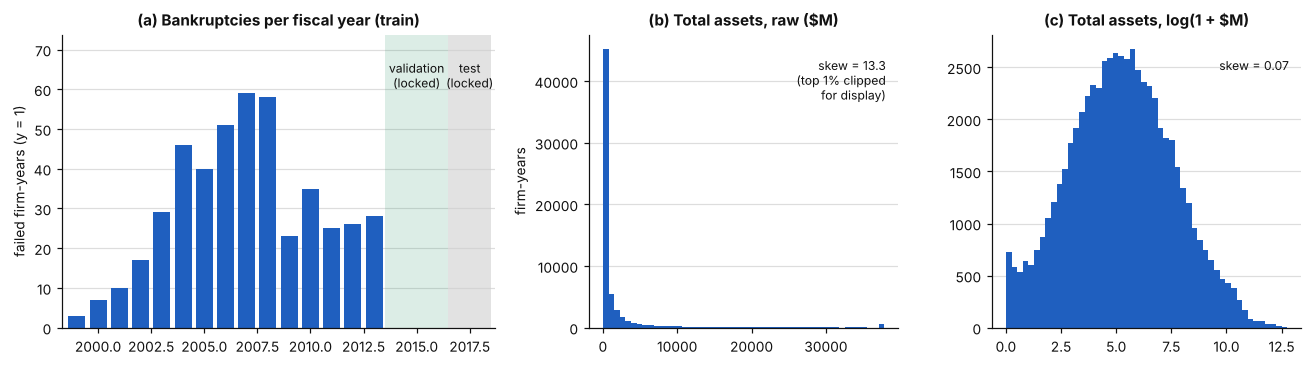

In [7]:
# Figure 1 — shape of the problem: rare, time-varying failures and heavily skewed dollar figures
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
val_fail = df[df.split == "validation"].groupby("year").size() * 0   # validation labels stay unexamined
ax[0].bar(by_year.index, by_year.failures, color=C_ALIVE, width=0.8)
ax[0].axvspan(TRAIN_END + 0.5, VAL_END + 0.5, color=C_VAL, alpha=0.15, lw=0)
ax[0].axvspan(VAL_END + 0.5, 2018.5, color=C_LOCK, alpha=0.6, lw=0)
ymax = by_year.failures.max() * 1.25
ax[0].text((TRAIN_END + VAL_END) / 2 + 0.5, ymax * 0.82, "validation\n(locked)", ha="center", fontsize=8)
ax[0].text((VAL_END + 2018) / 2 + 0.5, ymax * 0.82, "test\n(locked)", ha="center", fontsize=8)
ax[0].set(ylim=(0, ymax), xlim=(1998.3, 2018.7), title="(a) Bankruptcies per fiscal year (train)",
          ylabel="failed firm-years (y = 1)")
ax[0].grid(axis="x", visible=False)

ta = train.total_assets.clip(lower=0)
ax[1].hist(ta.clip(upper=ta.quantile(0.99)), bins=50, color=C_ALIVE)
ax[1].set(title="(b) Total assets, raw ($M)", ylabel="firm-years")
ax[1].text(0.96, 0.92, f"skew = {skew(ta):.1f}\n(top 1% clipped\nfor display)", transform=ax[1].transAxes,
           ha="right", va="top", fontsize=8)
ax[2].hist(np.log1p(ta), bins=50, color=C_ALIVE)
ax[2].set(title="(c) Total assets, log(1 + $M)")
ax[2].text(0.96, 0.92, f"skew = {skew(np.log1p(ta)):.2f}", transform=ax[2].transAxes, ha="right", va="top", fontsize=8)
for a in ax[1:]:
    a.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("figures/m06_fig1_problem_shape.png", dpi=250, bbox_inches="tight")
plt.show()

### 📝 Notes for the report

**Figure 1 caption (suggested):** *(a) Bankruptcies per fiscal year in the training years; validation and test years
are locked. (b) Total assets on the raw scale (top 1% clipped for display) is extremely right-skewed (skew 13.3).
(c) After log(1 + x) the distribution is almost symmetric (skew 0.07).* Point to make: dollar figures must be logged
or turned into ratios before they enter a linear model.

### 1.6 Distributions, skewness and outliers in the predictors
Signed log `sign(x)·log(1+|x|)` is used for display so negative values (losses) are kept.

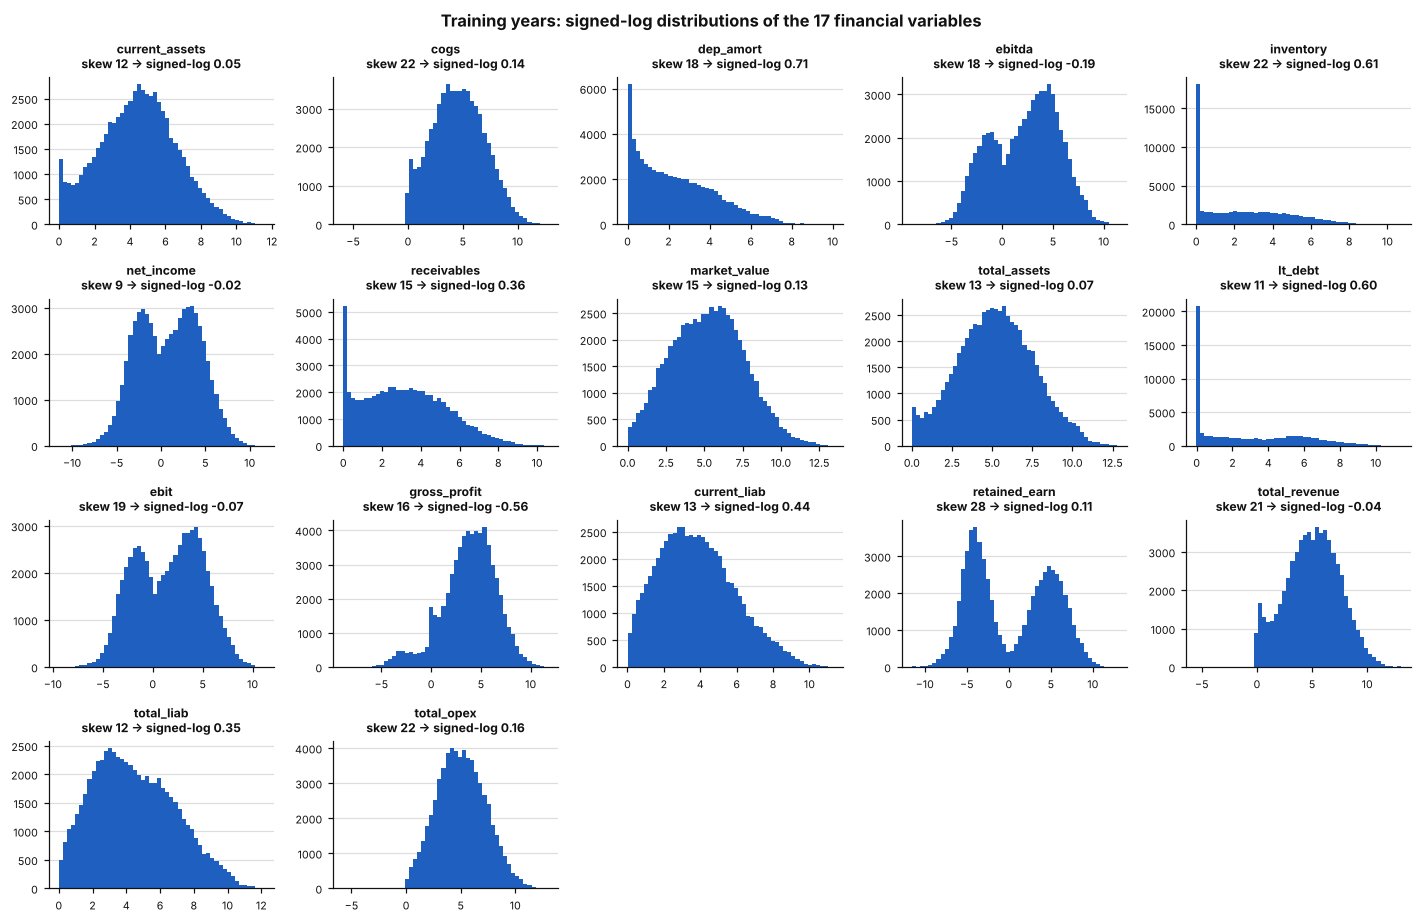

Rows with total assets < $1M (ratios explode): 1,682
Columns with >25% zeros: ['lt_debt']
Columns with >25% negative values (real losses): ['ebitda', 'net_income', 'ebit', 'retained_earn']


In [8]:
slog = lambda x: np.sign(x) * np.log1p(np.abs(x))
fig, axes = plt.subplots(4, 5, figsize=(13, 8.5))
for a, c in zip(axes.flat, RAW_KEEP):
    a.hist(slog(train[c]), bins=50, color=C_ALIVE)
    a.set_title(f"{c}\nskew {skew(train[c]):.0f} → signed-log {skew(slog(train[c])):.2f}", fontsize=8)
    a.tick_params(labelsize=7); a.grid(axis="x", visible=False)
for a in axes.flat[len(RAW_KEEP):]:
    a.axis("off")
fig.suptitle("Training years: signed-log distributions of the 17 financial variables", fontweight="bold")
fig.tight_layout()
fig.savefig("figures/m06_figA_distributions.png", dpi=200, bbox_inches="tight")
plt.show()

q01, q99 = train[RAW_KEEP].quantile(0.01), train[RAW_KEEP].quantile(0.99)
print(f"Rows with total assets < $1M (ratios explode): {(train.total_assets < 1).sum():,}")
print(f"Columns with >25% zeros: {feat_tab.index[feat_tab['% zero'] > 25].tolist()}")
print(f"Columns with >25% negative values (real losses): {feat_tab.index[feat_tab['% negative'] > 25].tolist()}")

### 📝 Notes for the report

* **Figure A (appendix):** every raw variable, shown on a *signed log* scale, sign(x)·log(1 + |x|), so negative values
  (losses) stay visible. Signed log is a display/baseline tool; the model uses ratios (Section 2).
* **Outliers:** 1,682 training rows have total assets under $1M; dividing by such small numbers produces extreme
  ratios. Outliers are real firms, so they are **not deleted**; instead each feature is **winsorized** (clipped at its
  1st and 99th percentile) inside the pipeline, with the cut-offs learned from each training fold only.

### 1.7 Predictor types and expected relationships with the response
All predictors are continuous (plus `Division`, categorical, when attached). The table compares each financial
ratio's **expected** direction from credit-analysis domain knowledge with what the training data show:
univariate ROC-AUC (0.5 = no signal) and the median for survivors vs failures. The ratios themselves are defined in
Section 2; this is a screening view only, not model selection.

In [9]:
def _div(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(np.abs(b) > 1e-9, a / b, np.nan)

def build_features(X):
    # Stateless row-wise arithmetic on raw + prior-year columns (learns nothing → safe inside the Pipeline)
    F = pd.DataFrame(index=X.index)
    # Altman's five ratios
    F["Working capital / assets"]   = _div(X.current_assets - X.current_liab, X.total_assets)
    F["Retained earnings / assets"] = _div(X.retained_earn, X.total_assets)
    F["EBIT / assets"]              = _div(X.ebit, X.total_assets)
    F["Market value / liabilities"] = _div(X.market_value, X.total_liab)
    F["Sales / assets"]             = _div(X.total_revenue, X.total_assets)
    # Leverage and liquidity
    F["Liabilities / assets"]       = _div(X.total_liab, X.total_assets)
    F["Long-term debt / assets"]    = _div(X.lt_debt, X.total_assets)
    F["Current ratio"]              = _div(X.current_assets, X.current_liab)
    # Profitability
    F["Net income / assets"]        = _div(X.net_income, X.total_assets)
    F["Gross margin"]               = _div(X.gross_profit, X.total_revenue)
    F["EBITDA / liabilities"]       = _div(X.ebitda, X.total_liab)
    # Size
    F["Log total assets"]           = np.log1p(X.total_assets.clip(lower=0))
    F["Log market value"]           = np.log1p(X.market_value.clip(lower=0))
    # Momentum: change since the prior year's report (missing when there is no t−1 report)
    F["Change in liabilities / assets"] = F["Liabilities / assets"] - _div(X.prev_total_liab, X.prev_total_assets)
    F["Change in net income / assets"]  = F["Net income / assets"] - _div(X.prev_net_income, X.prev_total_assets)
    F["Sales growth"]        = _div(X.total_revenue - X.prev_total_revenue, np.abs(X.prev_total_revenue))
    F["Market value growth"] = _div(X.market_value - X.prev_market_value, np.abs(X.prev_market_value))
    F = F.replace([np.inf, -np.inf], np.nan)
    if "Division" in X:
        F["Division"] = X["Division"].fillna("Unknown").astype(str)
    return F

def altman_z(F):
    return (1.2 * F["Working capital / assets"] + 1.4 * F["Retained earnings / assets"] + 3.3 * F["EBIT / assets"]
            + 0.6 * F["Market value / liabilities"] + 1.0 * F["Sales / assets"])

Ftr = build_features(train[INPUT_COLS])
NUM_FEATS = [c for c in Ftr.columns if c != "Division"]
STATIC = NUM_FEATS[:13]
MOMENTUM = NUM_FEATS[13:]
ALTMAN5 = NUM_FEATS[:5]
Ftr["Altman Z (1968)"] = altman_z(Ftr)

EXPECT = {"Working capital / assets": "↓ risk", "Retained earnings / assets": "↓ risk", "EBIT / assets": "↓ risk",
          "Market value / liabilities": "↓ risk", "Sales / assets": "unclear", "Liabilities / assets": "↑ risk",
          "Long-term debt / assets": "↑ risk", "Current ratio": "↓ risk", "Net income / assets": "↓ risk",
          "Gross margin": "↓ risk", "EBITDA / liabilities": "↓ risk", "Log total assets": "↓ risk",
          "Log market value": "↓ risk", "Change in liabilities / assets": "↑ risk",
          "Change in net income / assets": "↓ risk", "Sales growth": "↓ risk", "Market value growth": "↓ risk",
          "Altman Z (1968)": "↓ risk"}
rows = []
for c in NUM_FEATS + ["Altman Z (1968)"]:
    m = Ftr[c].notna().values
    auc = roc_auc_score(ytr[m], Ftr[c].values[m])
    obs = "↑ risk" if auc > 0.5 else "↓ risk"
    rows.append({"feature": c, "expected (domain)": EXPECT[c], "observed": obs,
                 "AUC": max(auc, 1 - auc),
                 "median survivors": Ftr.loc[m & (ytr == 0), c].median(),
                 "median failures": Ftr.loc[m & (ytr == 1), c].median(),
                 "matches": "—" if EXPECT[c] == "unclear" else ("yes" if EXPECT[c] == obs else "NO")})
uni = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)
uni.round(3)

,feature,expected (domain),observed,AUC,median survivors,median failures,matches
0,Market value / liabilities,↓ risk,↓ risk,0.806,2.259,0.295,yes
1,Liabilities / assets,↑ risk,↑ risk,0.771,0.494,0.902,yes
2,Altman Z (1968),↓ risk,↓ risk,0.766,2.807,-0.468,yes
3,Net income / assets,↓ risk,↓ risk,0.737,0.019,-0.222,yes
4,Change in liabilities / assets,↑ risk,↑ risk,0.734,0.001,0.137,yes
5,Current ratio,↓ risk,↓ risk,0.728,1.914,0.954,yes
6,Log market value,↓ risk,↓ risk,0.724,5.272,3.357,yes
7,Market value growth,↓ risk,↓ risk,0.723,0.045,-0.426,yes
8,Working capital / assets,↓ risk,↓ risk,0.713,0.216,-0.016,yes
9,EBITDA / liabilities,↓ risk,↓ risk,0.699,0.162,-0.017,yes


### 📝 Notes for the report

Use this table for **1c (predictor types and expected relationships)**.
* **Predictor types:** all 17 engineered predictors are continuous; `Division` (industry) is categorical.
* **Every ratio moves in the direction credit analysis predicts** ("matches = yes" for 16 of 17; sales/assets has no
  clear expected direction and is weak).
* **Strongest single signals (univariate ROC-AUC, 0.5 = none):** market value / liabilities **0.81** (median 2.26 for
  survivors vs 0.30 for failures), liabilities / assets **0.77** (0.49 vs 0.90), Altman Z 0.77, net income / assets
  0.74 (+0.02 vs −0.22), and the momentum feature **change in liabilities / assets 0.73** (+0.00 vs +0.14).
* **Weakest:** sales / assets 0.56, long-term debt / assets 0.56, log total assets 0.57.
* This is a screening view (one feature at a time); the model in Section 4 judges features jointly.

In [10]:
# Altman Z zones: the benchmark's precision problem (fixed 1968 formula, nothing fitted)
zone = pd.cut(Ftr["Altman Z (1968)"], [-np.inf, 1.81, 2.99, np.inf],
              labels=["Distress (<1.81)", "Grey (1.81–2.99)", "Safe (>2.99)"])
zt = pd.DataFrame({"zone": zone, "y": ytr}).groupby("zone", observed=True).y.agg(["size", "sum", "mean"])
zt.columns = ["firm-years", "failures", "failure rate"]
zt["share of all failures"] = zt.failures / zt.failures.sum()
z = -Ftr["Altman Z (1968)"].fillna(Ftr["Altman Z (1968)"].median())
print(f"Altman Z on training years: ROC-AUC {roc_auc_score(ytr, z):.3f} | PR-AUC {average_precision_score(ytr, z):.4f} "
      f"(no-skill PR-AUC = {ytr.mean():.4f})")
zt.assign(**{"failure rate": (zt["failure rate"] * 100).round(2).astype(str) + "%",
             "share of all failures": (zt["share of all failures"] * 100).round(1).astype(str) + "%"})

Altman Z on training years: ROC-AUC 0.766 | PR-AUC 0.0186 (no-skill PR-AUC = 0.0073)


,firm-years,failures,failure rate,share of all failures
zone,,,,
Distress (<1.81),22443,352,1.57%,77.0%
Grey (1.81–2.99),10766,52,0.48%,11.4%
Safe (>2.99),29687,53,0.18%,11.6%


### 📝 Notes for the report

* **The benchmark's weakness, in numbers:** Altman Z's distress zone (Z < 1.81) flags 22,443 training firm-years
  (36% of all rows). It catches **77%** of failures (352 of 457), but **only 1.57%** of the firms it flags actually fail:
  about 63 false alarms for every real bankruptcy. That is the business problem this project addresses.
* Altman Z ranks failures reasonably (ROC-AUC 0.766) but its **PR-AUC is only 0.019**, about 2.5× the no-skill 0.007.

In [11]:
# How early does distress show up? Median ratios of failing firms by years before their y = 1 report
KEY = ["Liabilities / assets", "EBIT / assets", "Market value / liabilities", "Net income / assets"]
# Uses training-year labels only: a firm counts as "failing" only if its y = 1 report falls in 1999–2013,
# so firms that fail in the locked 2014–2018 years are never singled out here.
fail_in_train = train.groupby("company_name").y.transform("max").values == 1
ytf = (train.groupby("company_name").year.transform("max") - train.year).values      # years before the firm's last train report
ev = Ftr.loc[fail_in_train, KEY].assign(ytf=ytf[fail_in_train])
traj = ev[ev.ytf <= 5].groupby("ytf")[KEY].median().sort_index(ascending=False)
alive_ref = Ftr.loc[~fail_in_train, KEY].median()      # firms with no failure in the training years
traj.index = [f"t−{int(k)}" if k else "t (y = 1)" for k in traj.index]
print("Firms with no failure in 1999–2013 (medians):", alive_ref.round(3).to_dict())
traj.round(3)

Firms with no failure in 1999–2013 (medians): {'Liabilities / assets': 0.489, 'EBIT / assets': 0.051, 'Market value / liabilities': 2.312, 'Net income / assets': 0.021}


,Liabilities / assets,EBIT / assets,Market value / liabilities,Net income / assets
t−5,0.589,0.012,1.248,-0.030
t−4,0.641,-0.002,0.988,-0.061
t−3,0.633,0.002,1.120,-0.040
t−2,0.669,-0.005,0.912,-0.056
t−1,0.758,-0.024,0.618,-0.098
t (y = 1),0.902,-0.070,0.295,-0.222


### 📝 Notes for the report

* **Distress builds for years and accelerates at the end.** For the 457 firms that fail within the training years,
  median liabilities / assets is **0.59 five years before** the final report, 0.76 one year before and **0.90 in the
  final report**, against **0.49** for firms with no failure. EBIT / assets turns negative about four years out;
  market value / liabilities falls from 1.25 to 0.30 (firms with no failure: 2.31).
* This is the evidence for the **momentum features** in Section 2: the *change* from last year carries information a
  single-year snapshot misses.
* Only failures inside 1999–2013 are used here, so no information from the locked years enters the exploration.

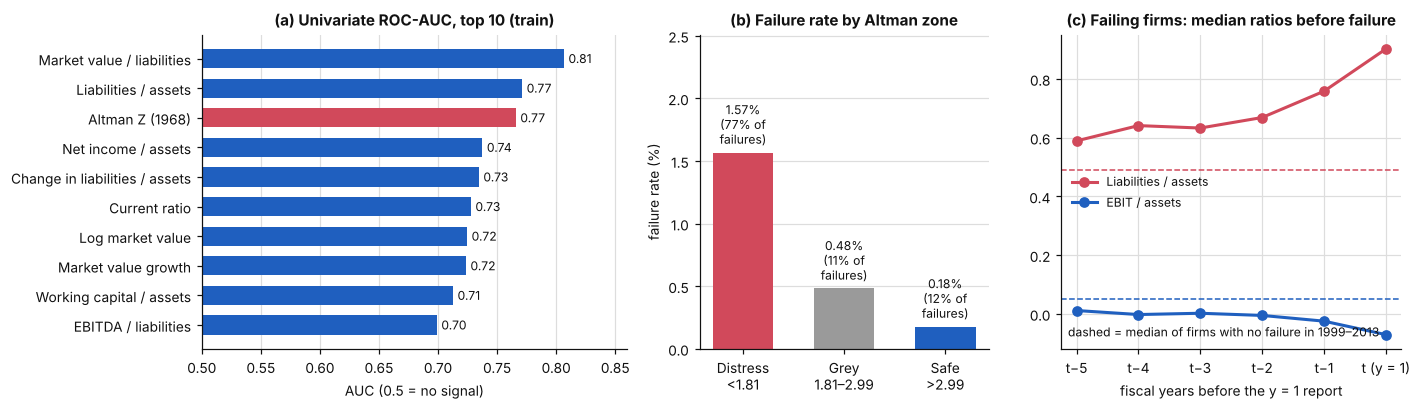

In [12]:
# Figure 2 — where the signal is
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.25, 0.85, 1]))
top = uni.head(10).iloc[::-1]
ax[0].barh(top.feature, top.AUC - 0.5, left=0.5, height=0.65,
           color=[C_FAIL if f == "Altman Z (1968)" else C_ALIVE for f in top.feature])
for i, a_ in enumerate(top.AUC):
    ax[0].text(a_ + 0.004, i, f"{a_:.2f}", va="center", fontsize=8)
ax[0].set(xlim=(0.5, max(0.86, top.AUC.max() + 0.04)), title="(a) Univariate ROC-AUC, top 10 (train)",
          xlabel="AUC (0.5 = no signal)")
ax[0].grid(axis="y", visible=False)

rates = zt["failure rate"].values * 100
ax[1].bar(range(3), rates, color=[C_FAIL, "#9a9a9a", C_ALIVE], width=0.6)
ax[1].set_xticks(range(3), ["Distress\n<1.81", "Grey\n1.81–2.99", "Safe\n>2.99"])
for i, (r, sh) in enumerate(zip(rates, zt["share of all failures"])):
    ax[1].text(i, r + rates.max() * 0.03, f"{r:.2f}%\n({sh:.0%} of\nfailures)", ha="center", va="bottom", fontsize=8)
ax[1].set(ylim=(0, rates.max() * 1.6), title="(b) Failure rate by Altman zone", ylabel="failure rate (%)")
ax[1].grid(axis="x", visible=False)

x = np.arange(len(traj))
ax[2].plot(x, traj["Liabilities / assets"], color=C_FAIL, lw=2, marker="o", label="Liabilities / assets")
ax[2].axhline(alive_ref["Liabilities / assets"], color=C_FAIL, lw=1, ls="--")
ax[2].plot(x, traj["EBIT / assets"], color=C_ALIVE, lw=2, marker="o", label="EBIT / assets")
ax[2].axhline(alive_ref["EBIT / assets"], color=C_ALIVE, lw=1, ls="--")
ax[2].set_xticks(x, traj.index)
ax[2].set(title="(c) Failing firms: median ratios before failure", xlabel="fiscal years before the y = 1 report")
ax[2].legend(loc="center left", fontsize=8)
ax[2].text(0.02, 0.04, "dashed = median of firms with no failure in 1999–2013", transform=ax[2].transAxes, fontsize=8)
fig.tight_layout()
fig.savefig("figures/m06_fig2_signal.png", dpi=250, bbox_inches="tight")
plt.show()

### 📝 Notes for the report

**Figure 2 caption (suggested):** *(a) Univariate ROC-AUC of the ten strongest predictors (training years); Altman Z in
red. (b) Failure rate by Altman Z zone: the distress zone contains 77% of failures but only 1.57% of its firms fail.
(c) Median liabilities / assets and EBIT / assets of failing firms in the five years before their final report;
dashed lines are the medians of firms with no failure.*

Most correlated pairs (|ρ|):
Working capital / assets  Current ratio           0.92
EBIT / assets             EBITDA / liabilities    0.89
Log total assets          Log market value        0.88
EBIT / assets             Net income / assets     0.88
Net income / assets       EBITDA / liabilities    0.83
Liabilities / assets      Current ratio           0.72


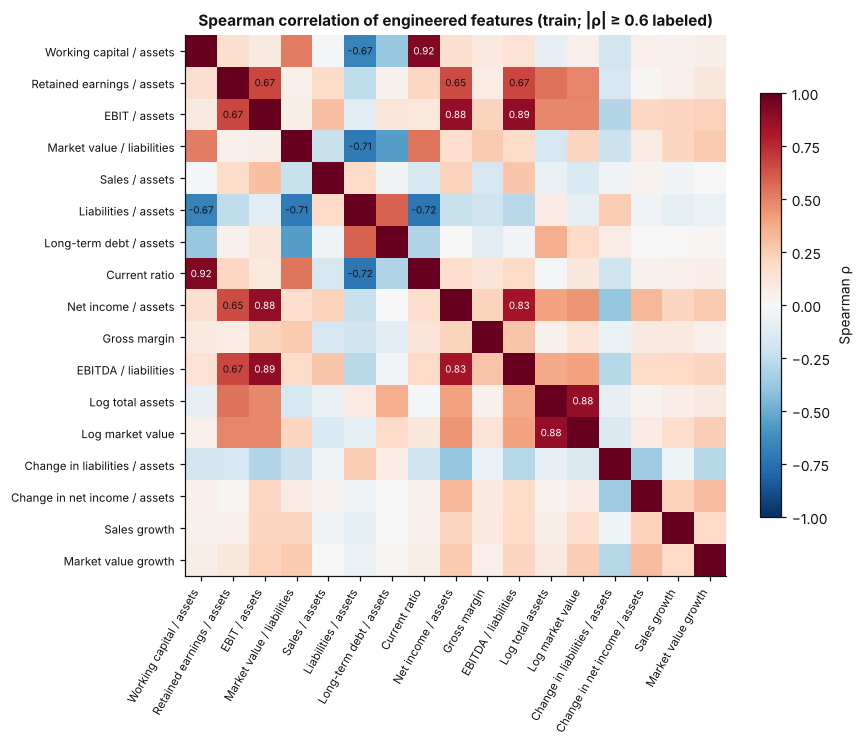

,firm_years,failures,rate
Division,,,
Retail,4538,54,1.19%
Mining,3299,36,1.09%
Transport/Utilities,5880,53,0.9%
Agri/Forestry,244,2,0.82%
Finance/RE,1684,13,0.77%
Manufacturing,30430,216,0.71%
Services,13877,70,0.5%
Wholesale,2364,11,0.47%
Construction,568,2,0.35%


In [13]:
# Correlation among the engineered predictors (Spearman, robust to skew/outliers)
corr = Ftr[NUM_FEATS].corr(method="spearman")
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
print("Most correlated pairs (|ρ|):")
print(pairs.abs().sort_values(ascending=False).head(6).round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 6.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_FEATS)), NUM_FEATS, rotation=60, ha="right", fontsize=7.5)
ax.set_yticks(range(len(NUM_FEATS)), NUM_FEATS, fontsize=7.5)
ax.grid(False)
for i in range(len(NUM_FEATS)):
    for j in range(len(NUM_FEATS)):
        if i != j and abs(corr.iloc[i, j]) >= 0.6:
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(corr.iloc[i, j]) > 0.75 else INK)
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title("Spearman correlation of engineered features (train; |ρ| ≥ 0.6 labeled)")
fig.tight_layout()
fig.savefig("figures/m06_fig3_correlation.png", dpi=250, bbox_inches="tight")
plt.show()

if HAS_DIVISION:
    DIV = {"A": "Agri/Forestry", "B": "Mining", "C": "Construction", "D": "Manufacturing", "E": "Transport/Utilities",
           "F": "Wholesale", "G": "Retail", "H": "Finance/RE", "I": "Services", "J": "Public admin"}
    ind = train.groupby("Division").y.agg(firm_years="size", failures="sum", rate="mean")
    ind.index = ind.index.map(lambda d: DIV.get(d, d))
    display(ind.sort_values("rate", ascending=False).assign(rate=lambda t: (t.rate * 100).round(2).astype(str) + "%"))

### 📝 Notes for the report

* **Strong multicollinearity:** working capital / assets vs current ratio ρ = **0.92**; EBIT / assets vs EBITDA /
  liabilities 0.89; log total assets vs log market value 0.88; EBIT / assets vs net income / assets 0.88; net income /
  assets vs EBITDA / liabilities 0.83. Correlated predictors make individual logistic coefficients unstable and can flip
  their signs, which motivates **LASSO** feature selection in Section 4 and reading correlated ratios as a group.
* **Industry:** failure rates differ by sector: Retail 1.19%, Mining 1.09%, Transport/Utilities 0.90% vs Services 0.50%
  and Wholesale 0.47% (Construction, Agriculture and Public administration have too few firms to judge). Industry is not
  a model input yet; adding it is a next step.

In [14]:
# Drift within the training years (test years never summarized)
early, late = (train.year <= 2005).values, (train.year >= 2006).values
drift = pd.DataFrame({"1999–2005": Ftr.loc[early, KEY + ["Log total assets"]].median(),
                      f"2006–{TRAIN_END}": Ftr.loc[late, KEY + ["Log total assets"]].median()})
drift.loc["failure rate"] = [ytr[early].mean(), ytr[late].mean()]
drift.round(4)

,1999–2005,2006–2013
Liabilities / assets,0.494,0.498
EBIT / assets,0.043,0.054
Market value / liabilities,2.178,2.287
Net income / assets,0.013,0.024
Log total assets,4.966,5.534
failure rate,0.005,0.010


### 📝 Notes for the report

* **Drift inside the training years:** the failure rate doubles from 0.5% (1999–2005) to 1.0% (2006–2013) and firms
  get larger (median log assets 4.97 → 5.53, roughly 1.75× the median assets), while the typical ratios barely move.
* Because the population changes over time, we validate with **time-ordered folds** (train on earlier years, validate
  on a later year) rather than shuffled folds.

## Section 2 — Feature engineering
### 2.1 Why ratios instead of raw dollars
Raw dollar figures cannot be compared across firms: $100M of debt is crushing for a small firm and trivial for a
large one, and every dollar column has skew between 7 and 25 (§1.6). Credit analysts scale balance-sheet items by
firm size, so we build **17 new features** from the 17 raw columns plus each firm's prior-year report. They fall into
five groups that map to the standard dimensions of credit risk.

In [15]:
ENG = pd.DataFrame([
    ("Working capital / assets", "(current assets − current liabilities) / total assets", "Liquidity", "Altman (1968) ratio 1: short-term cushion"),
    ("Retained earnings / assets", "retained earnings / total assets", "Profitability", "Altman ratio 2: cumulative profitability and firm age"),
    ("EBIT / assets", "EBIT / total assets", "Profitability", "Altman ratio 3: operating return on assets"),
    ("Market value / liabilities", "market value / total liabilities", "Leverage", "Altman ratio 4: equity cushion the market sees above debt"),
    ("Sales / assets", "total revenue / total assets", "Efficiency", "Altman ratio 5: asset turnover"),
    ("Liabilities / assets", "total liabilities / total assets", "Leverage", "Book leverage; > 1 means negative equity"),
    ("Long-term debt / assets", "long-term debt / total assets", "Leverage", "Debt burden that must be refinanced"),
    ("Current ratio", "current assets / current liabilities", "Liquidity", "Can the firm pay bills due this year?"),
    ("Net income / assets", "net income / total assets", "Profitability", "Bottom-line return after interest and taxes"),
    ("Gross margin", "gross profit / total revenue", "Profitability", "Pricing power over direct costs"),
    ("EBITDA / liabilities", "EBITDA / total liabilities", "Coverage", "Cash-flow proxy relative to everything owed"),
    ("Log total assets", "log(1 + total assets)", "Size", "Larger firms have more access to credit; log removes skew"),
    ("Log market value", "log(1 + market value)", "Size", "Market-based size; log removes skew"),
    ("Change in liabilities / assets", "leverage(t) − leverage(t−1)", "Momentum (temporal)", "Distress accelerates: leverage jumps in the final year"),
    ("Change in net income / assets", "ROA(t) − ROA(t−1)", "Momentum (temporal)", "Deteriorating profitability"),
    ("Sales growth", "(revenue(t) − revenue(t−1)) / |revenue(t−1)|", "Momentum (temporal)", "Shrinking demand"),
    ("Market value growth", "(MV(t) − MV(t−1)) / |MV(t−1)|", "Momentum (temporal)", "Market losing confidence before the filing"),
], columns=["feature", "formula", "group", "rationale"]).set_index("feature")
ENG

,formula,group,rationale
feature,,,
Working capital / assets,(current assets − current liabilities) / total...,Liquidity,Altman (1968) ratio 1: short-term cushion
Retained earnings / assets,retained earnings / total assets,Profitability,Altman ratio 2: cumulative profitability and f...
EBIT / assets,EBIT / total assets,Profitability,Altman ratio 3: operating return on assets
Market value / liabilities,market value / total liabilities,Leverage,Altman ratio 4: equity cushion the market sees...
Sales / assets,total revenue / total assets,Efficiency,Altman ratio 5: asset turnover
Liabilities / assets,total liabilities / total assets,Leverage,Book leverage; > 1 means negative equity
Long-term debt / assets,long-term debt / total assets,Leverage,Debt burden that must be refinanced
Current ratio,current assets / current liabilities,Liquidity,Can the firm pay bills due this year?
Net income / assets,net income / total assets,Profitability,Bottom-line return after interest and taxes


### 📝 Notes for the report

**Why these 17 features (rubric: "create ≥ 1 new feature with justification").** All 17 are new; none exist in the
raw file.
* **Ratios instead of dollars.** Dividing by total assets, total liabilities or revenue makes a $50M firm comparable
  with a $50B firm ($100M of debt is fatal for one and trivial for the other) and removes most of the size skew.
* **Altman's five ratios** (working capital, retained earnings, EBIT and sales over assets; market value over
  liabilities) are the most-cited bankruptcy predictors. Using them lets the model learn its own weights on the same
  inputs Altman weighted by hand in 1968.
* **Leverage and liquidity** (liabilities / assets, long-term debt / assets, current ratio): bankruptcy is a debt
  problem; these measure how much the firm owes and whether it can pay this year's bills.
* **Profitability and coverage** (net income / assets, gross margin, EBITDA / liabilities): whether operations generate
  enough to service debt; EBITDA-based coverage mirrors how lenders write loan covenants.
* **Size** (log total assets, log market value): larger firms fail less (more access to credit); the log removes the
  extreme skew (13.3 → 0.07).
* **Momentum** (change in leverage, change in ROA, sales growth, market value growth): see §2.2.
* **Design choices:** division by ~0 returns *missing*, not infinity; features are row-wise arithmetic that learn
  nothing from other firms, so they cannot leak; the Altman Z-score itself is kept as the **benchmark**, not as an input
  (it is a fixed weighted sum of five features already in the set).

### 2.2 Highlighted new features: momentum (temporal) features
The ratios above describe a firm at one moment. Our event-time analysis (§1.7, Figure 2c) shows distress is a
**process**: failing firms' median liabilities / assets rises steadily over five years and then jumps sharply in the
final report. A firm whose leverage moved from 0.60 to 0.85 in one year is riskier than one that has sat at 0.85 for a
decade, but a single-year ratio treats them the same. The four **momentum features** capture that change by comparing
year *t* with the firm's own year *t−1* report. They are known at prediction time (the prior report is already public),
so they introduce no leakage. They are missing when the prior report does not exist (a firm's first year, or a gap);
that is handled in Section 3.

We also keep the **Altman Z-score** (a fixed 1968 weighting of the first five ratios) as the **benchmark**, not as a
model input: it is a linear combination of five features already in the set, so adding it would be redundant for a
linear model.

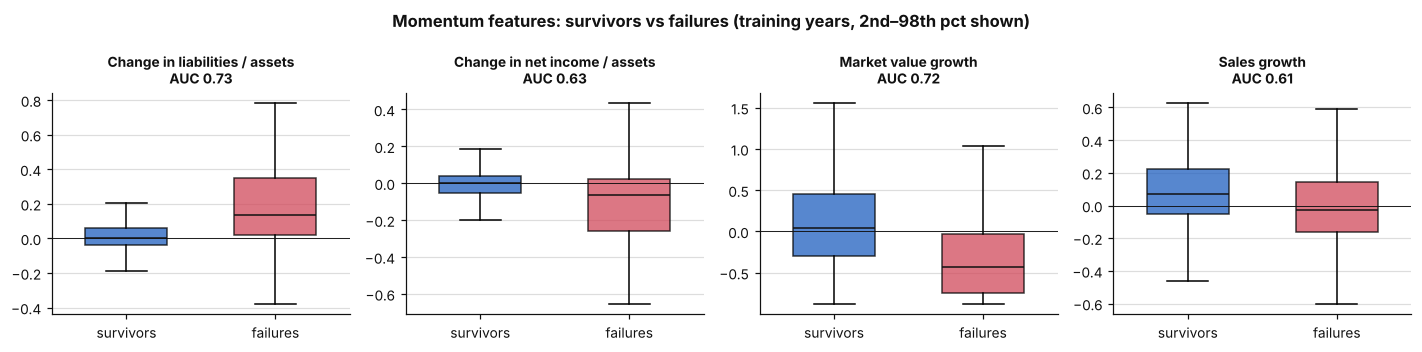

Missing share of each momentum feature (train): {'Change in liabilities / assets': 0.141, 'Change in net income / assets': 0.141, 'Sales growth': 0.141, 'Market value growth': 0.141}


In [16]:
# Do the momentum features separate failures? Distributions for survivors vs failures (training years)
show = ["Change in liabilities / assets", "Change in net income / assets", "Market value growth", "Sales growth"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for a, c in zip(axes, show):
    s = Ftr[c]
    lo, hi = s.quantile(0.02), s.quantile(0.98)
    data = [s[(ytr == 0)].dropna().clip(lo, hi), s[(ytr == 1)].dropna().clip(lo, hi)]
    bp = a.boxplot(data, tick_labels=["survivors", "failures"], showfliers=False, patch_artist=True, widths=0.55)
    for patch, col in zip(bp["boxes"], [C_ALIVE, C_FAIL]):
        patch.set_facecolor(col); patch.set_alpha(0.75)
    for med in bp["medians"]:
        med.set_color(INK)
    auc = uni.set_index("feature").loc[c, "AUC"]
    a.set_title(f"{c}\nAUC {auc:.2f}", fontsize=9)
    a.axhline(0, color=INK, lw=0.6)
    a.grid(axis="x", visible=False)
fig.suptitle("Momentum features: survivors vs failures (training years, 2nd–98th pct shown)", fontweight="bold")
fig.tight_layout()
fig.savefig("figures/m06_fig4_momentum.png", dpi=250, bbox_inches="tight")
plt.show()
print("Missing share of each momentum feature (train):", Ftr[MOMENTUM].isna().mean().round(3).to_dict())

### 📝 Notes for the report

* **Momentum features separate failures:** change in liabilities / assets AUC **0.73** (median +0.00 for survivors vs
  **+0.14** for failures); market value growth 0.72 (+4.5% vs **−42.6%**); change in net income / assets 0.63; sales
  growth 0.61 (+6.9% vs −2.5%).
* **Figure 4 caption (suggested):** *Momentum features for survivors and failures (training years, 2nd–98th percentile
  shown). Failing firms add leverage and lose market value in the year before their final report.*
* They are **missing for 14.1%** of training rows (no prior-year report); handled in Section 3.

### 2.3 Does feature engineering improve performance? (5-fold time-ordered CV, training years only)
To measure the impact, we fit the same simple class-weighted logistic regression on four feature sets and compare
cross-validated **PR-AUC** (area under the precision-recall curve), our primary metric because failures are rare
(no-skill PR-AUC ≈ prevalence ≈ 0.007).

* **A. Raw dollars**: the 17 raw columns, signed-log transformed (no engineering)
* **B. Altman's 5 ratios**
* **C. 13 static ratios** (all groups except momentum)
* **D. All 17 ratios** (C + the 4 momentum features)

**CV design.** 5 time-ordered, expanding-window folds inside 1999–2013: fold *k* trains on all years before
2009+*k* and validates on that single year (2009, …, 2013). A shuffled k-fold would let a model train on 2012 and
predict 2005, which a lender can never do. Every step (feature building, winsorizing at the 1st/99th percentiles,
median imputation with missing-indicators, scaling) sits inside the pipeline, so it is refit on each training fold.
Section 4 repeats the comparison with feature selection and a firm-grouped 5-fold check.

In [17]:
class Winsorizer(BaseEstimator, TransformerMixin):
    # Clip each column to [lower, upper] quantiles learned in fit (training fold only)
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_, self.hi_ = X.quantile(self.lower).values, X.quantile(self.upper).values
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

def raw_signed_log(X):
    return pd.DataFrame({c: slog(X[c]) for c in RAW_KEEP}, index=X.index)

def make_pipe(builder, cols):
    numeric = Pipeline([("clip", Winsorizer()),
                        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scale", StandardScaler())])
    pre = ColumnTransformer([("num", numeric, cols)])
    model = LogisticRegression(class_weight="balanced", max_iter=5000)
    return Pipeline([("features", FunctionTransformer(builder)), ("pre", pre), ("model", model)])

years = train.year.values
folds = [(np.where(years < v)[0], np.where(years == v)[0]) for v in range(TRAIN_END - 4, TRAIN_END + 1)]
print(pd.DataFrame([{"validate on": v, "train rows": len(tr), "val rows": len(va), "val failures": int(ytr[va].sum())}
                    for v, (tr, va) in zip(range(TRAIN_END - 4, TRAIN_END + 1), folds)]).to_string(index=False))

Xtr = train[INPUT_COLS]
SETS = {"A. Raw dollars (signed log)": (raw_signed_log, RAW_KEEP),
        "B. Altman's 5 ratios": (build_features, ALTMAN5),
        "C. 13 static ratios": (build_features, STATIC),
        "D. All 17 ratios (+ momentum)": (build_features, NUM_FEATS)}
fold_scores, summary = {}, []
for name, (builder, cols) in SETS.items():
    cv = cross_validate(make_pipe(builder, cols), Xtr, ytr, cv=folds, scoring=["average_precision", "roc_auc"])
    fold_scores[name] = cv["test_average_precision"]
    summary.append({"feature set": name, "n features": len(cols),
                    "CV PR-AUC (mean)": cv["test_average_precision"].mean(),
                    "PR-AUC (sd)": cv["test_average_precision"].std(),
                    "CV ROC-AUC (mean)": cv["test_roc_auc"].mean()})

az = np.array([average_precision_score(ytr[va], z.values[va]) for _, va in folds])
summary.append({"feature set": "Benchmark: Altman Z (no fitting)", "n features": 1,
                "CV PR-AUC (mean)": az.mean(), "PR-AUC (sd)": az.std(),
                "CV ROC-AUC (mean)": np.mean([roc_auc_score(ytr[va], z.values[va]) for _, va in folds])})
summary.append({"feature set": "No-skill (prevalence)", "n features": 0,
                "CV PR-AUC (mean)": np.mean([ytr[va].mean() for _, va in folds]), "PR-AUC (sd)": np.nan,
                "CV ROC-AUC (mean)": 0.5})
fe = pd.DataFrame(summary).set_index("feature set")
gain = fold_scores["D. All 17 ratios (+ momentum)"] - fold_scores["C. 13 static ratios"]
print(f"\nMomentum features: mean PR-AUC gain (D − C) = {gain.mean():+.4f}; better in {int((gain > 0).sum())} of 5 folds")
fe.round(4)

 validate on  train rows  val rows  val failures
        2009       45046      3743            23
        2010       48789      3625            35
        2011       52414      3513            25
        2012       55927      3485            26
        2013       59412      3484            28



Momentum features: mean PR-AUC gain (D − C) = +0.0074; better in 4 of 5 folds


,n features,CV PR-AUC (mean),PR-AUC (sd),CV ROC-AUC (mean)
feature set,,,,
A. Raw dollars (signed log),17,0.115,0.042,0.914
B. Altman's 5 ratios,5,0.034,0.011,0.847
C. 13 static ratios,13,0.063,0.028,0.894
D. All 17 ratios (+ momentum),17,0.071,0.023,0.884
Benchmark: Altman Z (no fitting),1,0.022,0.006,0.803
No-skill (prevalence),0,0.008,NaN,0.500


### 📝 Notes for the report

**Results of the feature-engineering test (5 time-ordered folds, class-weighted logistic regression):**
* **Engineered ratios add signal step by step:** Altman's 5 ratios with learned weights **0.034** (already 1.5× the
  fixed-weight Altman Z at 0.022) → 13 static ratios **0.063** → all 17 with momentum **0.071**.
* **Momentum features help:** +0.0074 PR-AUC over the static set, better in **4 of 5** folds.
* **All 17 ratios vs Altman Z: 0.071 vs 0.022, about 3.1×.** No-skill is 0.008.
* **Important and honest finding: set A (raw dollars, signed-log) scored highest, 0.115.** It is not "no engineering":
  it is log-transformed, and in a linear model the difference of two logs is the log of their ratio
  (log MV − log liabilities = log(MV / liabilities)), so the model can build log-scale ratios itself while also seeing
  firm size. Our ratios enter on their raw scale, where even after winsorizing their long tails dominate. The
  diagnostic in **§4d** confirms that putting the ratios on a log scale lifts them from 0.071 to 0.091.
  **Framing for the report:** feature engineering clearly helps (B → C → D, momentum), and the *scale* of the features
  matters as much as their content; log-scaled ratios are the first improvement for the next milestone. We keep the
  ratio set as the baseline because it is interpretable and standard in credit analysis.
* **ROC-AUC and PR-AUC can disagree:** the 13 static ratios have a higher ROC-AUC (0.894) than all 17 (0.884) but a
  lower PR-AUC. ROC-AUC rewards ranking the whole list; PR-AUC rewards a clean top of the list, which is what a credit
  analyst reviewing a watch list needs. This is why PR-AUC is the selection metric.

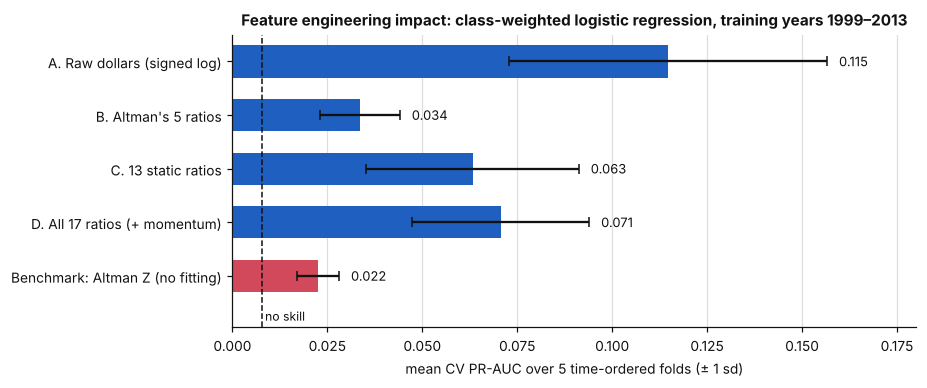

In [18]:
# Figure 5 — impact of feature engineering on CV PR-AUC
order = list(SETS) + ["Benchmark: Altman Z (no fitting)"]
vals = fe.loc[order, "CV PR-AUC (mean)"].values
sds = fe.loc[order, "PR-AUC (sd)"].values
fig, ax = plt.subplots(figsize=(8.5, 3.6))
cols = [C_ALIVE] * len(SETS) + [C_FAIL]
ax.barh(range(len(order))[::-1], vals, xerr=sds, color=cols, height=0.6, capsize=3, ecolor=INK)
span = np.nanmax(vals + np.nan_to_num(sds))
for i, v, sd in zip(range(len(order))[::-1], vals, np.nan_to_num(sds)):
    ax.text(v + sd + span * 0.02, i, f"{v:.3f}", va="center", fontsize=8.5)
ax.set_xlim(0, span * 1.15)
ax.axvline(fe.loc["No-skill (prevalence)", "CV PR-AUC (mean)"], color=INK, ls="--", lw=1)
ax.text(fe.loc["No-skill (prevalence)", "CV PR-AUC (mean)"], -0.75, " no skill", fontsize=8, va="center")
ax.set_ylim(-0.95, len(order) - 0.5)
ax.set_yticks(range(len(order))[::-1], order)
ax.set(xlabel="mean CV PR-AUC over 5 time-ordered folds (± 1 sd)",
       title="Feature engineering impact: class-weighted logistic regression, training years 1999–2013")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("figures/m06_fig5_fe_impact.png", dpi=250, bbox_inches="tight")
plt.show()

### 📝 Notes for the report

**Figure 5 caption (suggested):** *Mean cross-validated PR-AUC (± 1 SD over five time-ordered folds, 2009–2013) for
four feature sets and the Altman Z benchmark; dashed line = no skill.*

### 2.4 Key numbers for the report
Copy these into Sections 1–2 of `22_simple_model.pdf`.

In [19]:
d, c_, b, a_ = (fe.loc[k, "CV PR-AUC (mean)"] for k in
                ["D. All 17 ratios (+ momentum)", "C. 13 static ratios", "B. Altman's 5 ratios", "A. Raw dollars (signed log)"])
facts = {
    "dataset": f"{len(df):,} firm-years, {df.company_name.nunique():,} firms, {df.year.min()}–{df.year.max()}, {len(RAW)} financial columns",
    "training set": f"{len(train):,} firm-years, {int(train.y.sum())} failures ({train.y.mean():.2%})",
    "failure-rate range by year": f"{by_year.rate_pct.min():.2f}% ({by_year.rate_pct.idxmin()}) – {by_year.rate_pct.max():.2f}% ({by_year.rate_pct.idxmax()})",
    "total assets skew raw → log": f"{skew(train.total_assets):.1f} → {skew(np.log1p(train.total_assets.clip(lower=0))):.2f}",
    "strongest single signal": f"{uni.feature[0]} (AUC {uni.AUC[0]:.2f})",
    "Altman Z ROC-AUC / PR-AUC (train)": f"{roc_auc_score(ytr, z):.3f} / {average_precision_score(ytr, z):.4f}",
    "Altman distress zone": f"captures {zt['share of all failures'].iloc[0]:.0%} of failures; only {zt['failure rate'].iloc[0]:.2%} of flagged firms fail",
    "leverage of failing firms t−5 → t": f"{traj['Liabilities / assets'].iloc[0]:.2f} → {traj['Liabilities / assets'].iloc[-1]:.2f} (no-failure firms {alive_ref['Liabilities / assets']:.2f})",
    "highest Spearman ρ": f"{pairs.abs().max():.2f}",
    "momentum features missing": f"{Ftr[MOMENTUM].isna().mean().max():.1%} of training rows",
    "CV PR-AUC: raw → Altman-5 → static → all 17": f"{a_:.3f} → {b:.3f} → {c_:.3f} → {d:.3f}",
    "momentum gain (D − C)": f"{gain.mean():+.4f}, better in {int((gain > 0).sum())}/5 folds",
    "all-17 logistic vs Altman Z (CV PR-AUC)": f"{d:.3f} vs {az.mean():.3f} ({d / az.mean():.1f}×)",
}
pd.Series(facts, name="value").to_frame()

,value
dataset,"78,682 firm-years, 8,971 firms, 1999–2018, 18 ..."
training set,"62,896 firm-years, 457 failures (0.73%)"
failure-rate range by year,0.06% (1999) – 1.50% (2008)
total assets skew raw → log,13.3 → 0.07
strongest single signal,Market value / liabilities (AUC 0.81)
Altman Z ROC-AUC / PR-AUC (train),0.766 / 0.0186
Altman distress zone,captures 77% of failures; only 1.57% of flagge...
leverage of failing firms t−5 → t,0.59 → 0.90 (no-failure firms 0.49)
highest Spearman ρ,0.92
momentum features missing,14.1% of training rows


## Section 3 — Handling missing values
### 3.1 Where values are missing, and why
The raw Kaggle file has **no missing cells** (§1.1). Missing values appear only after feature engineering, for two
structural reasons:
1. **No prior-year report.** The four momentum features need the firm's year *t−1* report. It does not exist in a
   firm's first year in the data, or when the firm skipped a year (710 firms have gaps).
2. **Zero denominators.** A ratio is set to missing (not infinity) when its denominator is essentially zero, for
   example the current ratio of a firm reporting zero current liabilities.

In [20]:
miss = pd.DataFrame({
    "missing rows": Ftr[NUM_FEATS].isna().sum(),
    "% of train": (Ftr[NUM_FEATS].isna().mean() * 100).round(2),
    "% among survivors": (Ftr.loc[ytr == 0, NUM_FEATS].isna().mean() * 100).round(2),
    "% among failures": (Ftr.loc[ytr == 1, NUM_FEATS].isna().mean() * 100).round(2),
})
miss["reason"] = np.where(miss.index.isin(MOMENTUM), "no t−1 report (first year or gap)",
                          np.where(miss["missing rows"] > 0, "zero denominator", "—"))
first_year = (train.year == train.groupby("company_name").year.transform("min")).values
mom_missing = Ftr[MOMENTUM].isna().any(axis=1).values
any_missing = Ftr[NUM_FEATS].isna().any(axis=1).values
print(f"Raw columns missing: {int(train[RAW_KEEP].isna().sum().sum())} cells")
print(f"Training rows with ≥1 missing engineered feature: {any_missing.sum():,} ({any_missing.mean():.1%}); "
      f"failures among them: {int(ytr[any_missing].sum())} of {int(ytr.sum())}")
print(f"Momentum missing because it is the firm's first year: {(mom_missing & first_year).sum() / mom_missing.sum():.0%}; "
      f"because of a gap in the firm's years: {(mom_missing & ~first_year).sum() / mom_missing.sum():.0%}")
print(f"Failure rate when momentum is missing vs present: {ytr[mom_missing].mean():.2%} vs {ytr[~mom_missing].mean():.2%}")
miss[miss["missing rows"] > 0].sort_values("missing rows", ascending=False)

Raw columns missing: 0 cells
Training rows with ≥1 missing engineered feature: 8,872 (14.1%); failures among them: 12 of 457
Momentum missing because it is the firm's first year: 93%; because of a gap in the firm's years: 7%
Failure rate when momentum is missing vs present: 0.14% vs 0.82%


,missing rows,% of train,% among survivors,% among failures,reason
Change in liabilities / assets,8872,14.11,14.19,2.63,no t−1 report (first year or gap)
Change in net income / assets,8872,14.11,14.19,2.63,no t−1 report (first year or gap)
Sales growth,8872,14.11,14.19,2.63,no t−1 report (first year or gap)
Market value growth,8872,14.11,14.19,2.63,no t−1 report (first year or gap)


### 📝 Notes for the report

Use this for **Section 3 (identification)**.
* **Raw data: no missing values.** Missingness is created by feature engineering and affects only the **four momentum
  features**, all on the same **8,872 training rows (14.1%)**. None of the static ratios has missing values in the
  training years.
* **Cause:** 93% of these rows are a company's **first year** in the data (no prior report to compare with); 7% follow
  a **gap** in the company's filings.
* **The missingness is not random:** 14.2% of survivors' rows are missing but only 2.6% of failures' rows (12 of 457).
  The failure rate is **0.14% when momentum is missing vs 0.82% when present**: companies in their first year in the
  data rarely fail the following year. Missingness itself carries information, which is why we add a missing-indicator.

### 3.2 Strategy: median imputation plus a missing-indicator, fit inside the pipeline
* **Why not drop rows?** Dropping every row with a missing value removes each firm's first year and every
  post-gap year, around one in seven training rows, and with them a share of the rare failures we most need. It
  also biases the sample toward older, established firms, and a deployed model would still meet first-year firms
  it could not score.
* **Why the median?** The ratios are heavily skewed with extreme values, so the median is a far more typical
  value than the mean.
* **Why add an indicator?** Missingness here is *not random*: it marks a firm that is new to the data or just
  skipped a filing year. `SimpleImputer(add_indicator=True)` adds a 0/1 column per affected feature, so the model
  can learn whether "no prior report" itself carries risk instead of treating the filled-in median as real.
* **No leakage.** The median is learned from each training fold only, inside the pipeline.

### 3.3 Comparing alternatives (same 5 time-ordered folds, all 17 features, class-weighted logistic regression)
| Strategy | What it does |
|---|---|
| **Median + indicator** (chosen) | fill with training-fold median, add 0/1 "was missing" columns |
| Median only | same fill, no indicators |
| Zero-fill | fill with 0; for momentum this means "assume no change since last year" |
| Drop the momentum features | avoid the problem by not using them (= feature set C in §2.3) |
| Drop incomplete rows | complete-case analysis; scored only on complete validation rows, so it answers an easier question |

In [21]:
def make_pipe_imp(cols, imputer, C=1.0, extra=None):
    numeric = Pipeline([("clip", Winsorizer()), ("impute", imputer), ("scale", StandardScaler())])
    pre = ColumnTransformer([("num", numeric, cols)])
    model = LogisticRegression(class_weight="balanced", max_iter=5000, C=C)
    return Pipeline([("features", FunctionTransformer(build_features)), ("pre", pre), ("model", model)])

def time_cv(pipe, X, y, folds, rows_ok=None):
    # Score a pipeline on the time-ordered folds; rows_ok (bool array) restricts both fit and scoring rows
    ap, roc, n_val, n_pos = [], [], [], []
    for tr, va in folds:
        if rows_ok is not None:
            tr, va = tr[rows_ok[tr]], va[rows_ok[va]]
        pipe.fit(X.iloc[tr], y[tr])
        p = pipe.predict_proba(X.iloc[va])[:, 1]
        ap.append(average_precision_score(y[va], p)); roc.append(roc_auc_score(y[va], p))
        n_val.append(len(va)); n_pos.append(int(y[va].sum()))
    return np.array(ap), np.array(roc), int(np.sum(n_val)), int(np.sum(n_pos))

total_val_rows = sum(len(va) for _, va in folds)
total_val_pos = int(sum(ytr[va].sum() for _, va in folds))
strategies = {
    "Median + indicator (chosen)": (NUM_FEATS, SimpleImputer(strategy="median", add_indicator=True), None),
    "Median only": (NUM_FEATS, SimpleImputer(strategy="median"), None),
    "Zero-fill": (NUM_FEATS, SimpleImputer(strategy="constant", fill_value=0.0), None),
    "Drop momentum features": (STATIC, SimpleImputer(strategy="median", add_indicator=True), None),
    "Drop incomplete rows": (NUM_FEATS, SimpleImputer(strategy="median"), ~any_missing),
}
mv_rows, mv_folds = [], {}
for name, (cols, imp, ok) in strategies.items():
    ap, roc, nv, npos = time_cv(make_pipe_imp(cols, imp), Xtr, ytr, folds, ok)
    mv_folds[name] = ap
    mv_rows.append({"strategy": name, "CV PR-AUC (mean)": ap.mean(), "PR-AUC (sd)": ap.std(),
                    "CV ROC-AUC (mean)": roc.mean(), "validation rows scored": f"{nv:,} of {total_val_rows:,}",
                    "failures scored": f"{npos} of {total_val_pos}"})
mv = pd.DataFrame(mv_rows).set_index("strategy")
mv.round(4)

,CV PR-AUC (mean),PR-AUC (sd),CV ROC-AUC (mean),validation rows scored,failures scored
strategy,,,,,
Median + indicator (chosen),0.071,0.023,0.884,"17,850 of 17,850",137 of 137
Median only,0.073,0.025,0.886,"17,850 of 17,850",137 of 137
Zero-fill,0.073,0.025,0.887,"17,850 of 17,850",137 of 137
Drop momentum features,0.063,0.028,0.894,"17,850 of 17,850",137 of 137
Drop incomplete rows,0.079,0.026,0.888,"16,585 of 17,850",134 of 137


### 📝 Notes for the report

Use this for **Section 3 (strategy and comparison)**.
* **The three imputation methods tie:** median + indicator 0.071, median only 0.073, zero-fill 0.073. The 0.002
  difference is about a tenth of the fold-to-fold standard deviation (≈ 0.024): noise, not a ranking.
* **Dropping the momentum features hurts:** 0.063, about 0.01 lower than any version that keeps them. Imputing is
  better than discarding; momentum carries signal.
* **Dropping incomplete rows looks best (0.079) but is not comparable:** it removes 1,265 validation rows (scored on
  16,585 of 17,850) but only 3 failures (134 of 137). The removed rows are mostly first-year firms, which almost never
  fail, so the remaining test is easier. It also cannot work in practice: a lender must still score a firm that is new
  to the data.
* **Why we keep median + indicator:** when strategies tie, choose on reasoning. The median is robust to the skewed
  ratios; the indicator lets the model use the non-random missingness (0.14% vs 0.82% failure rate). LASSO in Section 4
  is free to drop the indicators but **keeps all four in 5 of 5 folds**, with negative coefficients (missing → lower
  risk), consistent with that finding. All imputation is fit on each training fold only.
* **Sentence for the report:** *"The three imputation strategies performed within 0.002 PR-AUC of each other, far
  below the fold-to-fold standard deviation (≈ 0.024), so the choice was made on reasoning: median imputation suits the
  skewed ratios, and a missing-indicator lets the model use the non-random missingness. Dropping the momentum features
  lowered PR-AUC to 0.063, confirming they add signal worth keeping; dropping incomplete rows is not comparable because
  it removes first-year firms from the validation sets."*

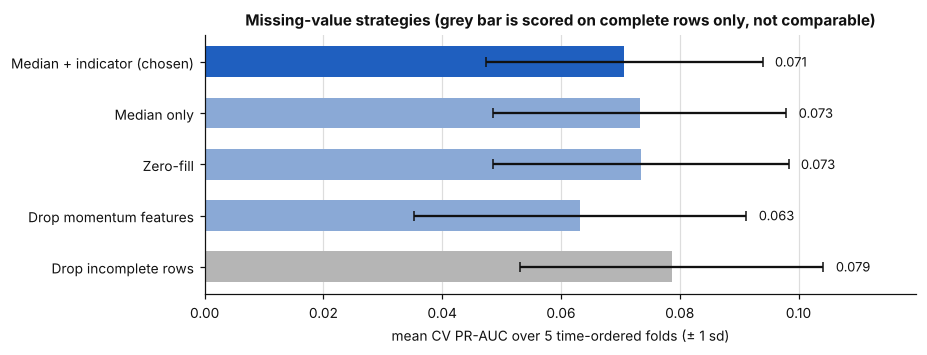

In [22]:
# Figure 6 — missing-value strategies
fig, ax = plt.subplots(figsize=(8.5, 3.3))
names = list(strategies)
vals, sds = mv["CV PR-AUC (mean)"].values, mv["PR-AUC (sd)"].values
colors = [C_ALIVE] + ["#8aa9d6"] * 3 + ["#b5b5b5"]
ypos = np.arange(len(names))[::-1]
ax.barh(ypos, vals, xerr=sds, color=colors, height=0.6, capsize=3, ecolor=INK)
span = np.nanmax(vals + sds)
for yp, v, sd in zip(ypos, vals, sds):
    ax.text(v + sd + span * 0.02, yp, f"{v:.3f}", va="center", fontsize=8.5)
ax.set_yticks(ypos, names)
ax.set_xlim(0, span * 1.15)
ax.set(xlabel="mean CV PR-AUC over 5 time-ordered folds (± 1 sd)",
       title="Missing-value strategies (grey bar is scored on complete rows only, not comparable)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("figures/m06_fig6_missing.png", dpi=250, bbox_inches="tight")
plt.show()

## Section 4 — Baseline model: logistic regression with feature selection inside k-fold CV
### 4a. Model choice
The response is binary, so the simplest reasonable model is **logistic regression**: it models the log-odds of
bankruptcy as a linear function of the features and outputs a probability, which is exactly the ranked risk score
we need. It is also interpretable: each standardized coefficient says how strongly a ratio pushes risk up or down,
which answers our second goal (identifying the drivers). Because only 0.7% of rows are failures, we use
`class_weight="balanced"` so the model does not ignore the rare class. Weighting changes the fitted coefficients and
inflates the predicted probabilities; whether it helps the ranking is tested in §4d. Threshold choice and calibration
are left to a later milestone.

### 4b. Implementation: feature selection inside 5-fold cross-validation
**Cross-validation (k = 5).** The same 5 time-ordered, expanding-window folds as §2.3 (validate on 2009, …, 2013,
each fold training only on earlier years). This is the course's honest CV for time-ordered data (nb08): a shuffled
k-fold would let the model learn from later years than it predicts. As a robustness check we repeat the final
comparison with a firm-grouped `GroupKFold(5)`, so no company appears in both the training and validation part of a fold.

**Metric.** CV **PR-AUC** (average precision) is the selection criterion. With 0.7% failures, accuracy is useless
(predicting "nobody fails" scores 99.3%) and ROC-AUC looks flattering; PR-AUC measures how clean the top of the risk
list is. No-skill PR-AUC equals the prevalence (≈ 0.007). We also track ROC-AUC and **recall in the riskiest 5%**
(the share of all failures caught if analysts review the top 5% of firms).

**Feature-selection procedures (both run inside the pipeline, so selection is redone on every training fold):**
1. **LASSO (L1-penalized) logistic regression.** The L1 penalty shrinks weak coefficients to exactly zero, so
   fitting the model *is* the feature selection. We search 13 penalty strengths C (smaller C = stronger penalty =
   fewer features) and pick the C with the best mean CV PR-AUC. We also report the **one-standard-error rule** model:
   the sparsest C whose CV PR-AUC is within one standard error of the best.
2. **Filter selection (`SelectKBest`)**, keeping the *k* features with the highest ANOVA F-score (computed on the
   training fold), followed by a standard (L2) logistic regression; k ∈ {3, 5, 8, 10, 13, all}.

In [23]:
import sklearn
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.feature_selection import SelectKBest, f_classif

SK18 = tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8)
L1 = dict(l1_ratio=1.0) if SK18 else dict(penalty="l1")      # same L1 penalty, new vs old scikit-learn API

def recall_at_top(y, s, frac=0.05):
    y, s = np.asarray(y), np.asarray(s)
    k = max(1, int(np.ceil(frac * len(s))))
    return y[np.argsort(-s)[:k]].sum() / max(1, y.sum())

def numeric_pre(cols):
    return ColumnTransformer([("num", Pipeline([("clip", Winsorizer()),
                                                 ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                                                 ("scale", StandardScaler())]), cols)])

def lasso_pipe(C=1.0):
    return Pipeline([("features", FunctionTransformer(build_features)), ("pre", numeric_pre(NUM_FEATS)),
                     ("model", LogisticRegression(C=C, solver="liblinear", class_weight="balanced",
                                                  max_iter=5000, random_state=RANDOM_SEED, **L1))])

C_GRID = np.logspace(-3, 1, 13)
gs = GridSearchCV(lasso_pipe(), {"model__C": C_GRID}, cv=folds, scoring="average_precision",
                  return_train_score=False, n_jobs=1)
gs.fit(Xtr, ytr)

path = pd.DataFrame({"C": C_GRID,
                     "CV PR-AUC (mean)": gs.cv_results_["mean_test_score"],
                     "PR-AUC (sd)": gs.cv_results_["std_test_score"]})
path["PR-AUC (se)"] = path["PR-AUC (sd)"] / np.sqrt(len(folds))
nnz = []
for C in C_GRID:     # coefficients that survive at each C (fit on all training years, for the path display only)
    m = lasso_pipe(C).fit(Xtr, ytr)
    names_out = m.named_steps["pre"].get_feature_names_out()
    coef = m.named_steps["model"].coef_.ravel()
    nnz.append(int(sum((abs(c) > 1e-8) for n, c in zip(names_out, coef) if "missingindicator" not in n)))
path["ratios kept (of 17)"] = nnz

best_i = int(path["CV PR-AUC (mean)"].idxmax())
thresh = path.loc[best_i, "CV PR-AUC (mean)"] - path.loc[best_i, "PR-AUC (se)"]
one_se_i = int(path.index[path["CV PR-AUC (mean)"] >= thresh].min())      # smallest C (sparsest) within 1 SE
C_BEST, C_1SE = C_GRID[best_i], C_GRID[one_se_i]
print(f"Best C = {C_BEST:.4g}: CV PR-AUC {path.loc[best_i, 'CV PR-AUC (mean)']:.4f}, {nnz[best_i]} ratios kept")
print(f"1-SE C = {C_1SE:.4g}: CV PR-AUC {path.loc[one_se_i, 'CV PR-AUC (mean)']:.4f}, {nnz[one_se_i]} ratios kept")
path.round(4)

Best C = 0.02154: CV PR-AUC 0.0722, 15 ratios kept
1-SE C = 0.002154: CV PR-AUC 0.0691, 11 ratios kept


,C,CV PR-AUC (mean),PR-AUC (sd),PR-AUC (se),ratios kept (of 17)
0,0.001,0.060,0.017,0.008,8
1,0.002,0.069,0.023,0.010,11
2,0.005,0.071,0.021,0.010,13
3,0.010,0.072,0.022,0.010,13
4,0.021,0.072,0.022,0.010,15
5,0.046,0.072,0.022,0.010,16
6,0.100,0.072,0.022,0.010,16
7,0.215,0.072,0.022,0.010,16
8,0.464,0.072,0.022,0.010,16
9,1.000,0.071,0.023,0.010,16


### 📝 Notes for the report

* **LASSO procedure:** for each of 13 penalty strengths C, the full pipeline (features → winsorize → impute → scale →
  L1 logistic) is refit on each of the 5 training folds and scored on the held-out year; the C with the best mean CV
  PR-AUC is selected. Because the penalty is fit inside each fold, **feature selection happens inside CV**.
* **Result:** best C = **0.0215**, CV PR-AUC **0.0722**, keeping **15 of 17** ratios. The one-standard-error rule picks
  C = 0.00215: 0.0691 with only **11** ratios.
* **The path is flat:** PR-AUC stays at 0.071–0.072 from C = 0.005 to C = 10 and only drops under a very strong penalty
  (0.060 with 8 ratios at C = 0.001). Several ratios are redundant: they can be removed without loss, but keeping them
  does not hurt either. ("Ratios kept" counts the model refit on all training years at each C.)

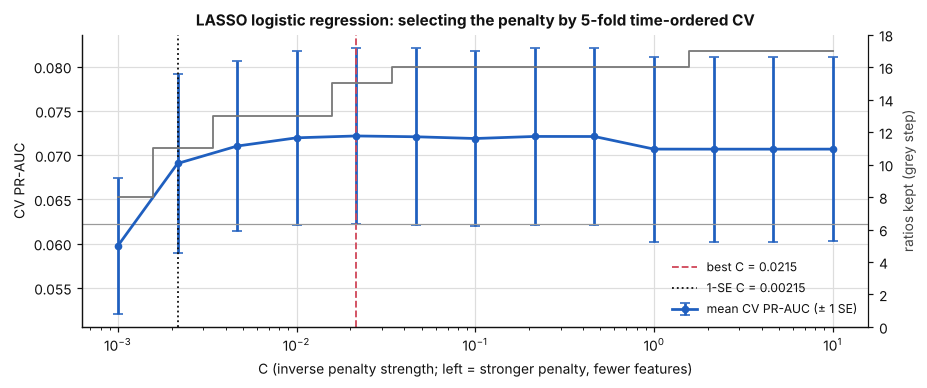

In [24]:
# Figure 7 — LASSO path: CV PR-AUC and number of ratios kept vs penalty strength
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.errorbar(path.C, path["CV PR-AUC (mean)"], yerr=path["PR-AUC (se)"], color=C_ALIVE, marker="o", ms=4,
            capsize=3, lw=1.8, label="mean CV PR-AUC (± 1 SE)")
ax.axvline(C_BEST, color=C_FAIL, ls="--", lw=1.2, label=f"best C = {C_BEST:.3g}")
ax.axvline(C_1SE, color=INK, ls=":", lw=1.2, label=f"1-SE C = {C_1SE:.3g}")
ax.axhline(thresh, color="#9a9a9a", lw=0.8)
ax.set_xscale("log")
ax.set(xlabel="C (inverse penalty strength; left = stronger penalty, fewer features)", ylabel="CV PR-AUC",
       title="LASSO logistic regression: selecting the penalty by 5-fold time-ordered CV")
ax2 = ax.twinx()
ax2.step(path.C, path["ratios kept (of 17)"], where="mid", color="#7a7a7a", lw=1.2)
ax2.set_ylabel("ratios kept (grey step)", color="#444444")
ax2.set_ylim(0, 18); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig("figures/m06_fig7_lasso_path.png", dpi=250, bbox_inches="tight")
plt.show()

### 📝 Notes for the report

**Figure 7 caption (suggested):** *LASSO logistic regression: mean CV PR-AUC (± 1 SE, blue) and number of ratios kept
(grey) across penalty strengths. Red dashed line = selected C (best CV PR-AUC); dotted line = one-standard-error choice.*

In [25]:
# Selection stability: in how many of the 5 training folds does LASSO (at the best C) keep each feature?
cv_best = cross_validate(lasso_pipe(C_BEST), Xtr, ytr, cv=folds, return_estimator=True,
                         scoring="average_precision")
coef_folds = []
for est in cv_best["estimator"]:
    names_out = [n.replace("num__", "") for n in est.named_steps["pre"].get_feature_names_out()]
    coef_folds.append(pd.Series(est.named_steps["model"].coef_.ravel(), index=names_out))
coef_folds = pd.concat(coef_folds, axis=1).fillna(0.0)
stab = pd.DataFrame({"folds selected (of 5)": (coef_folds.abs() > 1e-8).sum(axis=1),
                     "mean coefficient": coef_folds.mean(axis=1),
                     "sign consistent": (np.sign(coef_folds).nunique(axis=1) == 1)})
stab = stab.sort_values(["folds selected (of 5)", "mean coefficient"], key=lambda s: s.abs(), ascending=False)
stab.round(3)

,folds selected (of 5),mean coefficient,sign consistent
Log market value,5,-1.682,True
Log total assets,5,1.357,True
Current ratio,5,-0.954,True
EBITDA / liabilities,5,-0.530,True
missingindicator_Change in net income / assets,5,-0.452,True
Market value growth,5,-0.209,True
Change in liabilities / assets,5,0.176,True
EBIT / assets,5,-0.139,True
Market value / liabilities,5,0.120,True
Sales / assets,5,0.112,True


### 📝 Notes for the report

* **Selection is stable across folds:** 14 ratios and all 4 missing-indicators are kept in **5 of 5** training folds,
  all with the same sign every time except sales growth, whose coefficient is tiny and flips sign.
* **Dropped or unstable:** net income / assets (kept in 2 of 5 folds), working capital / assets (1 of 5) and retained
  earnings / assets (0 of 5). Each overlaps strongly with ratios that are kept: net income / assets with EBIT / assets
  (ρ = 0.88) and EBITDA / liabilities (0.83); working capital / assets with the current ratio (0.92). LASSO removes the
  redundant member of correlated pairs rather than discarding information.

In [26]:
# Procedure 2 — filter selection: SelectKBest (ANOVA F) + L2 logistic, k chosen by the same CV
def kbest_pipe(k):
    return Pipeline([("features", FunctionTransformer(build_features)), ("pre", numeric_pre(NUM_FEATS)),
                     ("select", SelectKBest(f_classif, k=k)),
                     ("model", LogisticRegression(class_weight="balanced", max_iter=5000))])

n_inputs = len(NUM_FEATS) + len(MOMENTUM)          # 17 ratios + 4 missing-indicators
K_GRID = [3, 5, 8, 10, 13, "all"]
gk = GridSearchCV(kbest_pipe(5), {"select__k": K_GRID}, cv=folds, scoring="average_precision", n_jobs=1)
gk.fit(Xtr, ytr)
kb = pd.DataFrame({"k": [str(k) for k in K_GRID], "CV PR-AUC (mean)": gk.cv_results_["mean_test_score"],
                   "PR-AUC (sd)": gk.cv_results_["std_test_score"]})
K_BEST = gk.best_params_["select__k"]
sel = gk.best_estimator_
kept = np.array([n.replace("num__", "") for n in sel.named_steps["pre"].get_feature_names_out()])[
    sel.named_steps["select"].get_support()]
print(f"Best k = {K_BEST}; features kept when refit on all training years: {[str(k) for k in kept]}")
kb.round(4)

Best k = all; features kept when refit on all training years: ['Working capital / assets', 'Retained earnings / assets', 'EBIT / assets', 'Market value / liabilities', 'Sales / assets', 'Liabilities / assets', 'Long-term debt / assets', 'Current ratio', 'Net income / assets', 'Gross margin', 'EBITDA / liabilities', 'Log total assets', 'Log market value', 'Change in liabilities / assets', 'Change in net income / assets', 'Sales growth', 'Market value growth', 'missingindicator_Change in liabilities / assets', 'missingindicator_Change in net income / assets', 'missingindicator_Sales growth', 'missingindicator_Market value growth']


,k,CV PR-AUC (mean),PR-AUC (sd)
0,3,0.031,0.009
1,5,0.049,0.021
2,8,0.039,0.011
3,10,0.041,0.012
4,13,0.040,0.012
5,all,0.071,0.023


### 📝 Notes for the report

* **Second selection procedure, filter method:** `SelectKBest` keeps the k features with the highest ANOVA F-score
  (computed on each training fold), then fits a standard logistic regression.
* **Every subset is worse than using all features:** k = 3: 0.031, k = 5: 0.049, k = 8–13: 0.039–0.041, all: **0.071**.
* **Why it fails:** the F-score judges each feature *alone*, so it keeps the individually strongest ratios, which are
  largely redundant with each other (leverage, market value / liabilities, Altman components), and drops size and
  momentum features that only help *in combination*. Univariate filters are poor selectors when predictors are
  correlated; the multivariate LASSO is the better procedure here. (k = 5 beating k = 8 reflects that redundancy and
  fold noise.)

In [27]:
# Model comparison on the 5 time-ordered folds (all numbers are cross-validated on 1999–2013 only)
def fold_metrics(pipe):
    ap, roc, rec = [], [], []
    oof = np.full(len(ytr), np.nan)
    for tr, va in folds:
        pipe.fit(Xtr.iloc[tr], ytr[tr])
        p = pipe.predict_proba(Xtr.iloc[va])[:, 1]
        oof[va] = p
        ap.append(average_precision_score(ytr[va], p)); roc.append(roc_auc_score(ytr[va], p))
        rec.append(recall_at_top(ytr[va], p))
    return np.array(ap), np.array(roc), np.array(rec), oof

def full_l2():
    return Pipeline([("features", FunctionTransformer(build_features)), ("pre", numeric_pre(NUM_FEATS)),
                     ("model", LogisticRegression(class_weight="balanced", max_iter=5000))])

MODELS = {
    "Logistic, all 17 ratios (no selection)": (full_l2(), len(NUM_FEATS)),
    f"SelectKBest, k = {K_BEST}": (kbest_pipe(K_BEST), K_BEST if K_BEST != "all" else n_inputs),
    f"LASSO, best C = {C_BEST:.3g}": (lasso_pipe(C_BEST), nnz[best_i]),
    f"LASSO, 1-SE C = {C_1SE:.3g}": (lasso_pipe(C_1SE), nnz[one_se_i]),
}
res, per_fold, oofs = [], {}, {}
for name, (pipe, nf) in MODELS.items():
    ap, roc, rec, oof = fold_metrics(pipe)
    per_fold[name], oofs[name] = ap, oof
    res.append({"model": name, "features": nf, "CV PR-AUC (mean)": ap.mean(), "PR-AUC (sd)": ap.std(),
                "CV ROC-AUC": roc.mean(), "recall in top 5%": rec.mean()})

zs = z.values
az_ap = np.array([average_precision_score(ytr[va], zs[va]) for _, va in folds])
per_fold["Altman Z (1968, no fitting)"] = az_ap
oofs["Altman Z (1968, no fitting)"] = np.where(np.isin(np.arange(len(ytr)), np.concatenate([va for _, va in folds])), zs, np.nan)
res.append({"model": "Altman Z (1968, no fitting)", "features": 5, "CV PR-AUC (mean)": az_ap.mean(),
            "PR-AUC (sd)": az_ap.std(),
            "CV ROC-AUC": np.mean([roc_auc_score(ytr[va], zs[va]) for _, va in folds]),
            "recall in top 5%": np.mean([recall_at_top(ytr[va], zs[va]) for _, va in folds])})
res.append({"model": "No-skill (prevalence)", "features": 0,
            "CV PR-AUC (mean)": np.mean([ytr[va].mean() for _, va in folds]), "PR-AUC (sd)": np.nan,
            "CV ROC-AUC": 0.5, "recall in top 5%": 0.05})
comp = pd.DataFrame(res).set_index("model")

SELECTED = f"LASSO, best C = {C_BEST:.3g}"
gain_z = per_fold[SELECTED] - az_ap
print(f"Selected model: {SELECTED}")
print(f"Paired gain over Altman Z: mean {gain_z.mean():+.4f} PR-AUC, better in {int((gain_z > 0).sum())} of 5 folds")
comp.round(4)

Selected model: LASSO, best C = 0.0215
Paired gain over Altman Z: mean +0.0497 PR-AUC, better in 5 of 5 folds


,features,CV PR-AUC (mean),PR-AUC (sd),CV ROC-AUC,recall in top 5%
model,,,,,
"Logistic, all 17 ratios (no selection)",17,0.071,0.023,0.884,0.443
"SelectKBest, k = all",21,0.071,0.023,0.884,0.443
"LASSO, best C = 0.0215",15,0.072,0.022,0.885,0.443
"LASSO, 1-SE C = 0.00215",11,0.069,0.023,0.884,0.388
"Altman Z (1968, no fitting)",5,0.022,0.006,0.803,0.142
No-skill (prevalence),0,0.008,NaN,0.500,0.050


### 📝 Notes for the report

**The main result for Section 4c.**
* **Selected model:** LASSO logistic regression, C = 0.0215, 15 ratios. CV PR-AUC **0.072** (SD 0.022), ROC-AUC 0.885,
  **recall in the riskiest 5% = 44.3%**.
* **Against Altman Z:** PR-AUC 0.022, ROC-AUC 0.803, recall in riskiest 5% = 14.2%. Our baseline is **3.2× better on
  PR-AUC**, mean gain +0.050, and **better in all 5 folds**. Against no skill (0.008) it is about 9×.
* **Plain-English version:** if analysts review the riskiest 5% of firms ranked by our model, they catch **44%** of the
  next year's bankruptcies; ranked by Altman Z, they catch **14%**.
* **Did selection help?** Only marginally: 0.0722 vs 0.0706 for the unpenalized 17-ratio model. LASSO's value is a
  simpler model (two fewer ratios) with equal performance. SelectKBest chose "all", so its row equals the unpenalized model.
* **Absolute PR-AUC is low (0.07)** because bankruptcies are rare: even a good model flags many survivors per failure.
  Judge it against the no-skill (0.008) and Altman (0.022) baselines, not against 1.

In [28]:
# Per-fold PR-AUC (shows the variation behind each mean)
pf = pd.DataFrame(per_fold, index=[f"validate {v}" for v in range(TRAIN_END - 4, TRAIN_END + 1)]).T
pf.loc["(failures in validation year)"] = [int(ytr[va].sum()) for _, va in folds]
pf.round(4)

,validate 2009,validate 2010,validate 2011,validate 2012,validate 2013
"Logistic, all 17 ratios (no selection)",0.052,0.064,0.085,0.108,0.044
"SelectKBest, k = all",0.052,0.064,0.085,0.108,0.044
"LASSO, best C = 0.0215",0.060,0.064,0.083,0.109,0.044
"LASSO, 1-SE C = 0.00215",0.062,0.062,0.069,0.110,0.042
"Altman Z (1968, no fitting)",0.015,0.029,0.021,0.029,0.018
(failures in validation year),23.000,35.000,25.000,26.000,28.000


### 📝 Notes for the report

* PR-AUC varies a lot by validation year (0.044–0.109 for the selected model) because each year has only 23–35
  failures: ranking one or two failures higher or lower moves the score noticeably. That is why we report means with
  standard deviations and compare models fold by fold.
* Altman Z is lower than every logistic model **in every year**.

In [29]:
# Robustness check: firm-grouped 5-fold CV (no company in both parts of a fold; years are mixed)
gkf = GroupKFold(n_splits=5)
groups = train.company_name.values
rob = []
for name in ["Logistic, all 17 ratios (no selection)", SELECTED]:
    cvr = cross_validate(MODELS[name][0], Xtr, ytr, cv=gkf, groups=groups, scoring=["average_precision", "roc_auc"])
    rob.append({"model": name, "GroupKFold PR-AUC (mean)": cvr["test_average_precision"].mean(),
                "PR-AUC (sd)": cvr["test_average_precision"].std(), "ROC-AUC": cvr["test_roc_auc"].mean()})
g_ap = [average_precision_score(ytr[va], zs[va]) for _, va in gkf.split(Xtr, ytr, groups)]
rob.append({"model": "Altman Z (1968, no fitting)", "GroupKFold PR-AUC (mean)": np.mean(g_ap),
            "PR-AUC (sd)": np.std(g_ap), "ROC-AUC": np.mean([roc_auc_score(ytr[va], zs[va]) for _, va in gkf.split(Xtr, ytr, groups)])})
rob = pd.DataFrame(rob).set_index("model")
rob.round(4)

,GroupKFold PR-AUC (mean),PR-AUC (sd),ROC-AUC
model,,,
"Logistic, all 17 ratios (no selection)",0.045,0.005,0.853
"LASSO, best C = 0.0215",0.045,0.005,0.854
"Altman Z (1968, no fitting)",0.020,0.003,0.766


### 📝 Notes for the report

* **Robustness check with firm-grouped 5-fold CV** (no company in both the training and validation part of a fold):
  selected model **0.045** vs Altman Z **0.020** (about 2.3×); ROC-AUC 0.854 vs 0.766. The conclusion holds under a
  different k-fold scheme.
* Absolute values differ from the time-ordered folds because the folds contain different mixes of years and PR-AUC
  depends on fold composition. Compare models *within* a CV scheme, not across schemes.

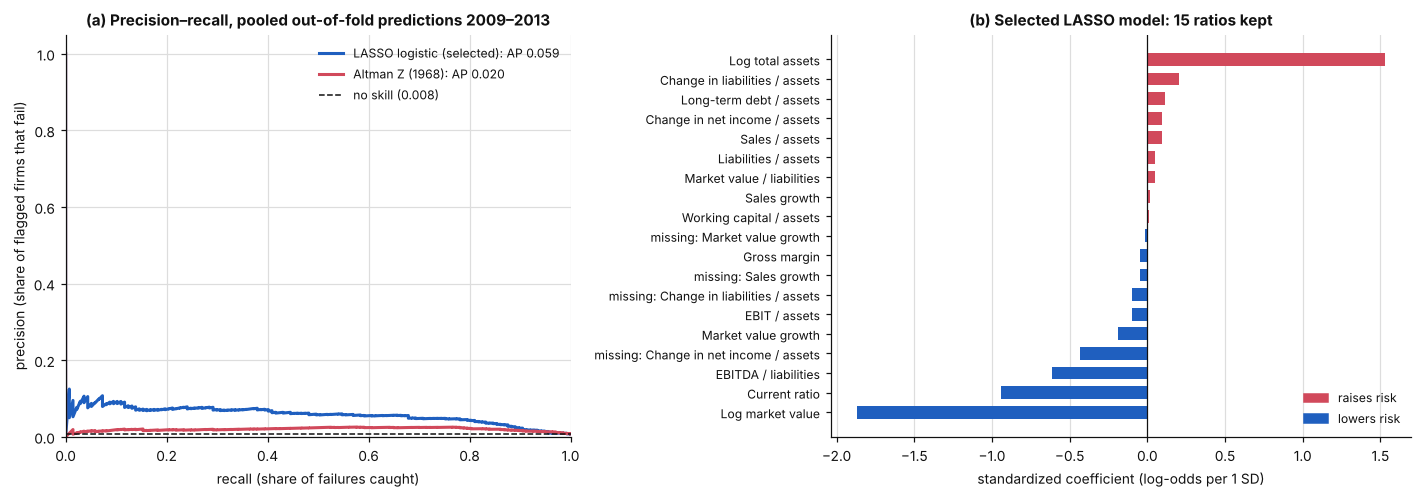

Ratios dropped by LASSO when refit on all training years: ['Retained earnings / assets', 'Net income / assets']

Odds multiplier per +1 SD (top 5 by size):
Log market value                  0.15
Log total assets                  4.61
Current ratio                     0.39
EBITDA / liabilities              0.54
Change in liabilities / assets    1.22


In [30]:
# Figure 8 — (a) out-of-fold precision-recall curves, (b) coefficients of the selected model refit on 1999–2013
from sklearn.metrics import precision_recall_curve
final = lasso_pipe(C_BEST).fit(Xtr, ytr)
names_out = [n.replace("num__", "").replace("missingindicator_", "missing: ") for n in final.named_steps["pre"].get_feature_names_out()]
coefs = pd.Series(final.named_steps["model"].coef_.ravel(), index=names_out)
coefs_nz = coefs[coefs.abs() > 1e-8].sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1, 1.15]))
mask = ~np.isnan(oofs[SELECTED])
for name, col, lab in [(SELECTED, C_ALIVE, "LASSO logistic (selected)"),
                       ("Altman Z (1968, no fitting)", C_FAIL, "Altman Z (1968)")]:
    prec, rec, _ = precision_recall_curve(ytr[mask], oofs[name][mask])
    ax[0].plot(rec, prec, color=col, lw=2, label=f"{lab}: AP {average_precision_score(ytr[mask], oofs[name][mask]):.3f}")
ax[0].axhline(ytr[mask].mean(), color=INK, ls="--", lw=1, label=f"no skill ({ytr[mask].mean():.3f})")
ax[0].set(xlabel="recall (share of failures caught)", ylabel="precision (share of flagged firms that fail)",
          title="(a) Precision–recall, pooled out-of-fold predictions 2009–2013", xlim=(0, 1), ylim=(0, None))
ax[0].legend(fontsize=8)

ax[1].barh(coefs_nz.index, coefs_nz.values, color=[C_FAIL if v > 0 else C_ALIVE for v in coefs_nz.values], height=0.65)
ax[1].axvline(0, color=INK, lw=0.8)
ax[1].set(xlabel="standardized coefficient (log-odds per 1 SD)",
          title=f"(b) Selected LASSO model: {int((coefs_nz.index.str.startswith('missing') == False).sum())} ratios kept")
ax[1].tick_params(axis="y", labelsize=8)
ax[1].grid(axis="y", visible=False)
ax[1].legend(handles=[Patch(color=C_FAIL, label="raises risk"), Patch(color=C_ALIVE, label="lowers risk")],
             loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig("figures/m06_fig8_model.png", dpi=250, bbox_inches="tight")
plt.show()

dropped = [f for f in NUM_FEATS if abs(coefs.get(f, 0.0)) <= 1e-8]
print("Ratios dropped by LASSO when refit on all training years:", dropped if dropped else "none")
odds = np.exp(coefs_nz.drop([i for i in coefs_nz.index if i.startswith("missing")], errors="ignore"))
print("\nOdds multiplier per +1 SD (top 5 by size):")
print(odds.iloc[np.argsort(-np.abs(np.log(odds.values)))][:5].round(2).to_string())

### 📝 Notes for the report

* **Final baseline (refit on all 1999–2013 data):** LASSO drops **retained earnings / assets** and **net income /
  assets**; 15 ratios plus the 4 missing-indicators remain.
* **Biggest effects (odds multiplier for a one-standard-deviation increase, holding the others fixed):** log market
  value **×0.15** (strongly protective), log total assets **×4.61**, current ratio **×0.39**, EBITDA / liabilities
  **×0.54**, change in liabilities / assets **×1.22** (rising leverage raises risk).
* **Why log total assets has a "risk-raising" sign:** it is correlated 0.88 with log market value. Holding market value
  fixed, more book assets means the market values the firm *below* its book assets, which is a distress signal. Read
  the two together: a large market value is protective, and on its own larger size lowers risk (univariate AUC 0.57,
  risk ↓). Similarly, market value / liabilities, the strongest single signal, gets only a small coefficient because
  log market value and the current ratio already carry its information.
* **Coefficients are conditional and not causal.** Use the §1.7 table for each ratio's direction on its own, and these
  coefficients for its contribution *given* the others.
* **Figure 8 caption (suggested):** *(a) Precision–recall curves from pooled out-of-fold predictions (2009–2013): the
  LASSO model holds far higher precision than Altman Z at every recall level. (b) Standardized coefficients of the
  final LASSO model; red raises risk, blue lowers it.*

### 4c. Interpretation and next steps
The cell below collects every number for Sections 3–4. Write the interpretation from it; the bullets after it are
the points to cover.

In [31]:
sel_row, z_row, l2_row = comp.loc[SELECTED], comp.loc["Altman Z (1968, no fitting)"], comp.loc["Logistic, all 17 ratios (no selection)"]
facts34 = {
    "rows with ≥1 missing engineered feature": f"{any_missing.mean():.1%} of training rows ({int(ytr[any_missing].sum())} failures)",
    "momentum missing: first year / gap": f"{(mom_missing & first_year).sum() / mom_missing.sum():.0%} / {(mom_missing & ~first_year).sum() / mom_missing.sum():.0%}",
    "failure rate, momentum missing vs present": f"{ytr[mom_missing].mean():.2%} vs {ytr[~mom_missing].mean():.2%}",
    "missing-value strategies (CV PR-AUC)": "; ".join(f"{k}: {v:.3f}" for k, v in mv["CV PR-AUC (mean)"].items()),
    "LASSO best C / ratios kept / CV PR-AUC": f"{C_BEST:.3g} / {nnz[best_i]} of 17 / {path.loc[best_i, 'CV PR-AUC (mean)']:.4f}",
    "LASSO 1-SE C / ratios kept / CV PR-AUC": f"{C_1SE:.3g} / {nnz[one_se_i]} of 17 / {path.loc[one_se_i, 'CV PR-AUC (mean)']:.4f}",
    "SelectKBest best k / CV PR-AUC": f"{K_BEST} / {gk.best_score_:.4f}",
    "selected model CV PR-AUC (sd)": f"{sel_row['CV PR-AUC (mean)']:.4f} ({sel_row['PR-AUC (sd)']:.4f})",
    "selected model CV ROC-AUC": f"{sel_row['CV ROC-AUC']:.3f}",
    "selected model recall in riskiest 5%": f"{sel_row['recall in top 5%']:.1%}",
    "Altman Z CV PR-AUC / ROC-AUC / top-5% recall": f"{z_row['CV PR-AUC (mean)']:.4f} / {z_row['CV ROC-AUC']:.3f} / {z_row['recall in top 5%']:.1%}",
    "selected vs Altman (PR-AUC)": f"{sel_row['CV PR-AUC (mean)'] / z_row['CV PR-AUC (mean)']:.1f}× ; gain {gain_z.mean():+.4f}, better in {int((gain_z > 0).sum())}/5 folds",
    "selected vs no-selection logistic (PR-AUC)": f"{sel_row['CV PR-AUC (mean)']:.4f} vs {l2_row['CV PR-AUC (mean)']:.4f}",
    "no-skill PR-AUC": f"{comp.loc['No-skill (prevalence)', 'CV PR-AUC (mean)']:.4f}",
    "GroupKFold check (selected / Altman)": f"{rob.loc[SELECTED, 'GroupKFold PR-AUC (mean)']:.4f} / {rob.loc['Altman Z (1968, no fitting)', 'GroupKFold PR-AUC (mean)']:.4f}",
    "ratios dropped by LASSO": ", ".join(dropped) if dropped else "none",
    "strongest positive / negative coefficient": f"{coefs_nz.idxmax()} / {coefs_nz.idxmin()}",
}
pd.Series(facts34, name="value").to_frame()

,value
rows with ≥1 missing engineered feature,14.1% of training rows (12 failures)
momentum missing: first year / gap,93% / 7%
"failure rate, momentum missing vs present",0.14% vs 0.82%
missing-value strategies (CV PR-AUC),Median + indicator (chosen): 0.071; Median onl...
LASSO best C / ratios kept / CV PR-AUC,0.0215 / 15 of 17 / 0.0722
LASSO 1-SE C / ratios kept / CV PR-AUC,0.00215 / 11 of 17 / 0.0691
SelectKBest best k / CV PR-AUC,all / 0.0706
selected model CV PR-AUC (sd),0.0722 (0.0221)
selected model CV ROC-AUC,0.885
selected model recall in riskiest 5%,44.3%


### 4d. Diagnostic: why do raw log-dollars beat the ratios? (evidence for next steps)
§2.3 showed the raw signed-log dollar set (0.115) beating the 17 ratios (0.071). This cell tests two explanations
on the same 5 time-ordered folds: (1) the ratios need a **log scale**; (2) `class_weight="balanced"` lowers PR-AUC.
These are diagnostics for the next milestone, not a change to the M06 baseline.

In [32]:
def diag_pipe(builder, cols, cw):
    numeric = Pipeline([("clip", Winsorizer()), ("impute", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scale", StandardScaler())])
    return Pipeline([("features", FunctionTransformer(builder)), ("pre", ColumnTransformer([("num", numeric, cols)])),
                     ("model", LogisticRegression(class_weight=cw, max_iter=5000))])

def log_ratios(X):                      # the same 17 ratios, put on a signed-log scale
    return build_features(X)[NUM_FEATS].apply(slog)

DIAG = {
    "17 ratios, balanced weights (= M06 baseline setup)": (build_features, NUM_FEATS, "balanced"),
    "17 ratios, no class weights": (build_features, NUM_FEATS, None),
    "17 ratios on signed-log scale, balanced": (log_ratios, NUM_FEATS, "balanced"),
    "17 ratios on signed-log scale, no class weights": (log_ratios, NUM_FEATS, None),
    "raw dollars signed-log, balanced (= set A)": (raw_signed_log, RAW_KEEP, "balanced"),
    "raw dollars signed-log, no class weights": (raw_signed_log, RAW_KEEP, None),
    "market value / liabilities alone": (build_features, ["Market value / liabilities"], "balanced"),
}
drows = []
for name, (b, cols, cw) in DIAG.items():
    cvr = cross_validate(diag_pipe(b, cols, cw), Xtr, ytr, cv=folds, scoring=["average_precision", "roc_auc"])
    drows.append({"variant": name, "CV PR-AUC (mean)": cvr["test_average_precision"].mean(),
                  "PR-AUC (sd)": cvr["test_average_precision"].std(), "CV ROC-AUC": cvr["test_roc_auc"].mean()})
diag = pd.DataFrame(drows).set_index("variant")
diag.round(4)

,CV PR-AUC (mean),PR-AUC (sd),CV ROC-AUC
variant,,,
"17 ratios, balanced weights (= M06 baseline setup)",0.071,0.023,0.884
"17 ratios, no class weights",0.094,0.036,0.884
"17 ratios on signed-log scale, balanced",0.091,0.043,0.904
"17 ratios on signed-log scale, no class weights",0.111,0.049,0.901
"raw dollars signed-log, balanced (= set A)",0.115,0.042,0.914
"raw dollars signed-log, no class weights",0.119,0.047,0.917
market value / liabilities alone,0.081,0.030,0.859


### 📝 Notes for the report

* **Log scale matters:** the same 17 ratios score **0.091** on a signed-log scale vs **0.071** raw, and ROC-AUC rises
  (0.884 → 0.904). A linear model assumes each feature's effect is a straight line; for ratios with long tails,
  risk is much closer to linear in their *log*.
* **Class weighting lowers PR-AUC here:** without `class_weight="balanced"` the 17 ratios score **0.094** vs 0.071,
  with identical ROC-AUC (0.884). Balanced weights push the model to separate the bulk of the list, at the cost of
  precision at the very top, which is exactly what PR-AUC measures.
* **Combined:** log-scaled ratios without class weights reach **0.111**, close to the raw signed-log set
  (0.115 balanced, 0.119 unweighted).
* **A single ratio, market value / liabilities, scores 0.081** on its own, above the 17-ratio balanced baseline. This
  means the multivariate baseline is held back by its setup (scale and weighting), not by a lack of signal.
* Both fixes will be selected by CV at the next milestone; tree-based models are insensitive to feature scale and
  are a natural complement.

### 📝 4c. Interpretation & next steps (write-up material)
**Performance summary.** The baseline is a LASSO logistic regression (C = 0.0215, 15 of 17 ratios plus 4
missing-indicators) selected by 5-fold time-ordered cross-validation on 1999–2013. It reaches a CV PR-AUC of **0.072**
(SD 0.022) and ROC-AUC 0.885, against **0.022** and 0.803 for the Altman Z-score and 0.008 for no skill: about
**3.2× Altman on PR-AUC, better in all 5 folds**. Reviewing the riskiest 5% of firms by our model catches **44%** of
next-year bankruptcies, vs 14% with Altman Z. A firm-grouped 5-fold check gives the same conclusion (0.045 vs 0.020).

**What feature selection did.** LASSO kept 15 ratios and dropped net income / assets and retained earnings / assets,
the redundant members of highly correlated groups; selection was stable (14 ratios kept in all 5 folds). Performance
was flat across a wide range of penalties (0.071–0.072), so the ratios overlap heavily: selection simplified the model
without changing accuracy. The univariate filter (SelectKBest) did worse at every k below "all", showing that features
matter jointly.

**Reflection: is more work needed? Yes.**
1. **Feature scale.** Raw signed-log dollars (0.115) beat our ratios (0.071), and putting the ratios on a log scale
   alone lifts them to 0.091 (§4d). Next milestone: log-scaled ratios, chosen by CV.
2. **Class weighting.** Balanced weights cost PR-AUC (0.094 without them, same ROC-AUC). Treat weighting as a tuning
   choice selected by CV, and handle the imbalance at the decision-threshold stage instead.
3. **Non-linear models.** Logistic regression cannot capture interactions (high leverage is worse when profits are
   negative) or threshold effects. Next: random forest, gradient boosting and a small neural network on the same
   pipeline and folds, adopted only if they beat this baseline by ≥ 0.02 PR-AUC.
4. **Industry.** Failure rates differ by sector (Retail 1.19% vs Services 0.50%); add `Division` as a one-hot feature.
5. **Decision use.** Choose a cost-based threshold (a missed bankruptcy costs far more than a false alarm) and calibrate
   probabilities on the 2014–2016 validation years; evaluate once on the locked 2017–2018 test years with bootstrap
   confidence intervals (only 5,737 test rows).

**Caveats.** PR-AUC varies a lot between folds (only 23–35 failures per validation year); class weighting distorts
probability levels, so current scores rank firms but are not calibrated probabilities; coefficients are conditional
associations, not causal effects.